# Consumer Financial Complaints: Pre-processing, Training and Modelling
**Springboard Data Science Career Track · Capstone Three** · Author: Jacob Paul

This notebook continues from `01_data_wrangling_and_eda.ipynb`. It turns the cleaned complaints into model-ready features, splits them by time, and trains and compares models for the two tasks defined in the [project proposal](../proposal/consumer-complaints-capstone-Proposal.pdf):

| Task | Target | Proposal success criterion |
|---|---|---|
| **Routing** (main) | `product_clean`, 11 harmonised products | Macro-F1 clearly above a majority-class baseline, with per-class results |
| Routing (secondary) | `issue` | Same metric; reported as a secondary result |
| **Relief** | "Closed with monetary relief" (1) vs "Closed with explanation" (0) | Average precision above the base rate **and** above a structured-fields-only model, on a later period than training; precision in the top 10% of the ranking |

| Step | DSM stage | Section |
|---|---|---|
| 1 | Load the cleaned data and define the targets | 1–2 |
| 2 | Outcome maturity: which months have final outcomes | 3 |
| 3 | Train / validation / test split (by time, grouped by repeated text) | 4 |
| 4 | Pre-processing: one-hot encoding, scaling, TF-IDF, all fitted on train only | 5 |
| 5 | Modelling: 4–5 models per task, tuned on validation | 6–8 |
| 6 | Model comparison, final model choice, single evaluation on test | 9–10 |
| 7 | Save models, metrics and figures | 11 |

**Run notes.** The notebook needs `data/processed/complaints_clean.parquet` from notebook 01. That file is the 20% random sample of the 21 CFPB archive exports, about 760k usable narratives. A full run took 29 minutes on a 16 GB MacBook Air (Apple M5, 8 cores used) and peaked at 5.9 GB of RAM. Close other memory-heavy applications first; swapping slows it down a lot. Every random step uses `RANDOM_STATE = 42`.

In [1]:
import ast
import os
import time
import warnings
from pathlib import Path

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report, confusion_matrix,
                             f1_score, precision_recall_curve, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
N_JOBS = 8                      # leave a couple of cores free on a 10-core laptop
# Quick-check mode for development only: NB02_DEV_FRAC=0.05 runs everything on 5% of each split. Default 0 = full run.
DEV_FRAC = float(os.environ.get("NB02_DEV_FRAC", "0"))
if DEV_FRAC:
    print(f"*** DEV MODE: {DEV_FRAC:.0%} of each split; results are NOT the reported ones ***")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "reports" / "figures"
REPORT_DIR = ROOT / "reports"
MODEL_DIR = ROOT / "models"
for d in (PROCESSED_DIR, FIG_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)


def savefig(name):
    """Save the current figure to reports/figures and show it."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


class Timer:
    """Context manager that records how long a block took (used for the compute column of the results table)."""
    def __enter__(self):
        self.t0 = time.perf_counter()
        return self

    def __exit__(self, *exc):
        self.seconds = time.perf_counter() - self.t0


print("pandas", pd.__version__, "| numpy", np.__version__, "| lightgbm", lgb.__version__)
print("Project root:", ROOT.name, "(all paths below are relative to it)")

pandas 3.0.3 | numpy 2.4.6 | lightgbm 4.7.0
Project root: consumer-complaints-capstone (all paths below are relative to it)


## 1. Load the cleaned data
Only the columns needed for modelling are read. Post-outcome columns (`company_public_response`, `timely_response`, `date_sent_to_company`, `days_to_company`) are **not loaded at all**, so they cannot leak into a feature by accident. `company_response` is loaded only to build the relief target. (`consumer_disputed` does not exist in the archive exports, see notebook 01.)

In [2]:
FEATURE_SOURCE_COLS = [
    "complaint_id", "date_received", "narrative", "narrative_hash",
    # routing targets / filing-time categorical fields
    "product_clean", "issue", "sub_product", "sub_issue", "company", "state", "zip3",
    "is_older_american", "is_servicemember",
    # text-shape features built in notebook 01 (row-wise counts, no fitted parameters)
    "word_count", "n_dollar", "xxxx_share", "upper_share", "n_exclaim",
    # outcome: used ONLY to build the relief target
    "company_response",
]
CLEAN_PATH = PROCESSED_DIR / "complaints_clean.parquet"
df = pd.read_parquet(CLEAN_PATH, columns=FEATURE_SOURCE_COLS, filters=[("text_usable", "==", True)])

# Categorical columns as plain strings (the one-hot encoder needs one consistent type; 'Missing' is already explicit)
CAT_SOURCE = ["product_clean", "issue", "sub_product", "sub_issue", "company", "state", "zip3", "company_response"]
for c in CAT_SOURCE:
    df[c] = df[c].astype(str)
df["narrative"] = df["narrative"].astype(str)
for c in ["is_older_american", "is_servicemember"]:
    df[c] = df[c].astype("float32")

print(f"Usable narratives loaded: {len(df):,} | {df['date_received'].min().date()} -> {df['date_received'].max().date()} "
      f"| {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")
display(df.head(3))

Usable narratives loaded: 758,548 | 2015-03-19 -> 2026-07-29 | 1.01 GB


,complaint_id,date_received,narrative,narrative_hash,product_clean,issue,sub_product,sub_issue,company,state,zip3,is_older_american,is_servicemember,word_count,n_dollar,xxxx_share,upper_share,n_exclaim,company_response
0,1767805,2016-02-01,I am very very very concerned with HESSA and the XXXX arrangement with priva...,3371173866343983808,Student loan,Dealing with my lender or servicer,Non-federal student loan,Received bad information about my loan,HIGHER EDUCATION STUDENT ASSISTANCE AUTHORITY (HESAA),NJ,080,0.0000,0.0000,65.0000,0.0000,0.0308,0.0419,0.0000,Closed with explanation
1,2535314,2017-06-18,"On or about XXXX XXXX , I went on line looking to refinance the mortgage on ...",5914986884777957075,Mortgage,Applying for a mortgage or refinancing an existing mortgage,Conventional home mortgage,Missing,"WYNDHAM CAPITAL MORTGAGE, INC",VA,222,1.0000,0.0000,350.0000,4.0000,0.0714,0.0957,0.0000,Closed with explanation
2,2598295,2017-08-08,"To : Consumer Financial Protection Bureau XXXX XXXX XXXX XXXX. XXXX, XXXX XX...",13022580017073910266,Student loan,Struggling to repay your loan,Federal student loan servicing,Can't get other flexible options for repaying your loan,COLLECTION TECHNOLOGY INCORPORATED,OH,436,0.0000,0.0000,"1,271.0000",1.0000,0.0724,0.0802,0.0000,Closed with explanation


## 2. Target definitions (following the proposal)
- **Routing:** `product_clean`, the 11 products of the CFPB's current taxonomy (harmonised in notebook 01, section 4.5). `issue` is a secondary routing target.
- **Relief (`relief`):** 1 = *Closed with monetary relief*, 0 = *Closed with explanation*. As in the proposal, complaints closed with **non-monetary relief**, still **in progress**, **untimely**, or with the 2012-era `Closed` labels are *left out* of the relief task.
- **Sensitivity label (`relief_sens`):** the proposal's check that also counts non-monetary relief as a negative. It is used only to re-score the final relief model in section 10.

> **Conflict with notebook 01:** notebook 01 defined relief against *every* closed outcome, including non-monetary relief (2.6% positives among narratives). The proposal's definition takes precedence here. Its base rate is higher (about 3.8%), because the many non-monetary closures are removed from the negatives.

In [3]:
resp = df["company_response"]
df["relief"] = np.select([resp.eq("Closed with monetary relief"), resp.eq("Closed with explanation")], [1.0, 0.0], np.nan)
df["relief_sens"] = np.select([resp.eq("Closed with monetary relief"),
                               resp.isin(["Closed with explanation", "Closed with non-monetary relief"])], [1.0, 0.0], np.nan)

target_summary = pd.DataFrame({
    "rows_with_label": [df["product_clean"].notna().sum(), df["relief"].notna().sum(), df["relief_sens"].notna().sum()],
    "positive_rate": [np.nan, df["relief"].mean(), df["relief_sens"].mean()],
}, index=["product_clean (11 classes)", "relief (proposal: monetary vs explanation)", "relief_sens (non-monetary = 0)"])
display(target_summary)
display(df["company_response"].value_counts().to_frame("narratives"))

,rows_with_label,positive_rate
product_clean (11 classes),758548,NaN
relief (proposal: monetary vs explanation),524540,0.0376
relief_sens (non-monetary = 0),755527,0.0261


,narratives
company_response,
Closed with explanation,504810
Closed with non-monetary relief,230987
Closed with monetary relief,19730
Untimely response,2256
Closed,739
In progress,24


## 3. Outcome maturity: which months have a final outcome?
The archive was frozen in August 2026. Complaints received shortly before that may still have been open, and their outcome would be recorded later. A model must never be trained or tested on months whose outcomes are not final. Maturity is measured on **all** complaints in the cleaned 20% sample, not only on narratives, because narratives almost never stay open.

**Rule (data-driven):** a month is *mature* if fewer than 1% of its complaints are still "In progress". The narrative opt-in rate is shown alongside it, because notebook 01 found that the narrative population changes completely in 2026.

,complaints,in_progress_share,untimely_share,narrative_optin
date_received,,,,
2025-07,"94,264",0.00%,0.23%,26.5%
2025-08,"99,041",0.00%,0.17%,21.9%
2025-09,"100,327",0.01%,0.17%,16.2%
2025-10,"103,823",0.04%,0.18%,14.5%
2025-11,"99,088",0.00%,0.23%,15.5%
2025-12,"102,017",0.00%,0.29%,11.0%
2026-01,"108,141",0.00%,0.30%,4.2%
2026-02,"99,757",0.00%,0.29%,2.5%
2026-03,"123,034",0.00%,0.30%,3.6%


First immature month (>= 1% in progress): 2026-07; immature months: ['2026-07', '2026-08']


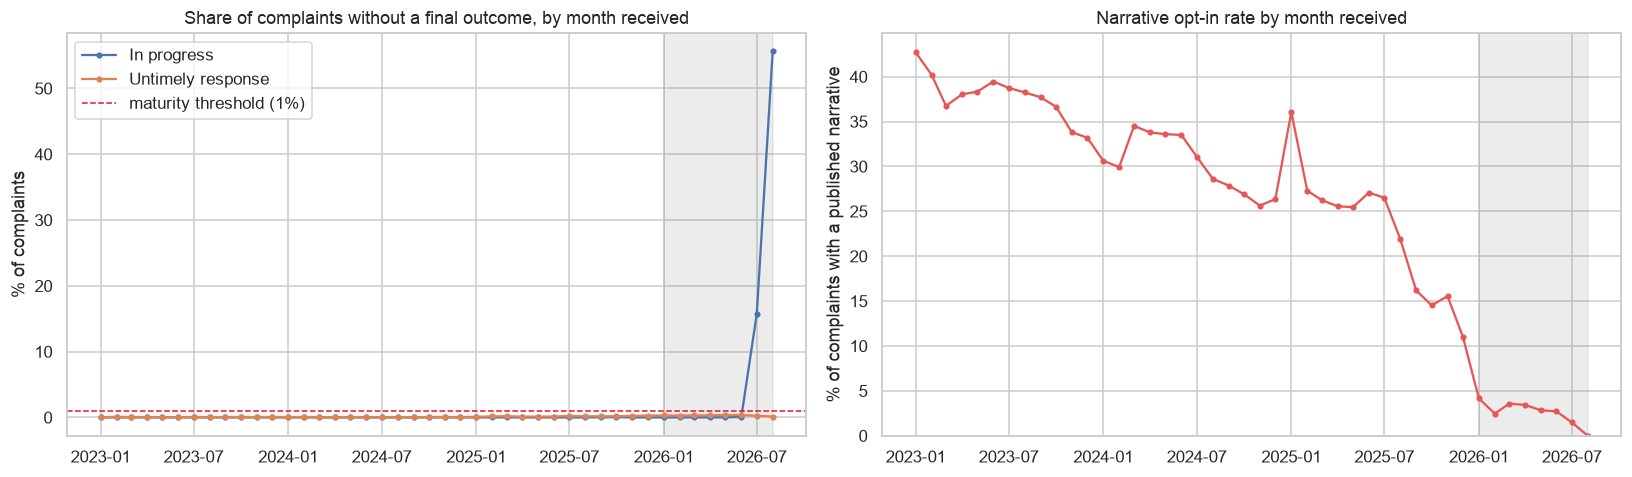

In [4]:
maturity_src = pd.read_parquet(CLEAN_PATH, columns=["date_received", "company_response", "has_narrative"])
m = maturity_src["date_received"].dt.to_period("M")
maturity = pd.DataFrame({
    "complaints": maturity_src.groupby(m).size(),
    "in_progress_share": maturity_src["company_response"].astype(str).eq("In progress").groupby(m).mean(),
    "untimely_share": maturity_src["company_response"].astype(str).eq("Untimely response").groupby(m).mean(),
    "narrative_optin": maturity_src["has_narrative"].groupby(m).mean(),
})
del maturity_src

MATURE_MAX_IN_PROGRESS = 0.01
immature_months = maturity.index[maturity["in_progress_share"] >= MATURE_MAX_IN_PROGRESS]
first_immature = immature_months.min()
display(maturity.loc["2025-07":].style.format({"complaints": "{:,.0f}", "in_progress_share": "{:.2%}",
                                                  "untimely_share": "{:.2%}", "narrative_optin": "{:.1%}"}))
print(f"First immature month (>= {MATURE_MAX_IN_PROGRESS:.0%} in progress): {first_immature}; "
      f"immature months: {[str(p) for p in immature_months]}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
recent = maturity.loc["2023-01":]
x = recent.index.to_timestamp()
axes[0].plot(x, recent["in_progress_share"] * 100, marker="o", ms=3, label="In progress")
axes[0].plot(x, recent["untimely_share"] * 100, marker="o", ms=3, label="Untimely response")
axes[0].axhline(MATURE_MAX_IN_PROGRESS * 100, color="crimson", ls="--", lw=1, label="maturity threshold (1%)")
axes[0].set_title("Share of complaints without a final outcome, by month received")
axes[0].set_ylabel("% of complaints")
axes[0].legend()
axes[1].plot(x, recent["narrative_optin"] * 100, marker="o", ms=3, color="#E45756")
axes[1].set_title("Narrative opt-in rate by month received")
axes[1].set_ylabel("% of complaints with a published narrative")
axes[1].set_ylim(bottom=0)
for ax in axes:
    ax.axvspan(pd.Timestamp("2026-01-01"), x.max(), color="grey", alpha=0.15)
savefig("20_outcome_maturity")

**Reading the maturity analysis**
- Outcomes are final for every month up to May 2026. "In progress" rises to 16% of July 2026 complaints and 56% of August 2026 complaints, so **July–August 2026 are immature and are excluded**. "Untimely response" (no answer from the company) also creeps up in 2026.
- Separately, the narrative opt-in rate collapses from about 20% to about 3% in **January 2026** (shaded). Notebook 01 showed that the remaining 2026 narratives are a different population: credit reporting falls from 74% to 4% of narratives. So 2026 is used neither for training nor for testing. Its **mature months (January–June 2026)** are scored once, with the final models, as an *out-of-distribution* slice.
- The modelling window is therefore **March 2015 (the first narratives) to December 2025**.

## 4. Train / validation / test split
**Why a time-based split.** The proposal evaluates models "on complaints from a later period than the training data", because relief rates and the product mix drift over the years (notebook 01, section 6.8). A random split would let the model learn from the future and would overstate performance.

| Split | Complaints received | Purpose |
|---|---|---|
| **Train** | 2015-03 → 2024-06 | Fit every encoder, scaler, vectoriser and model |
| **Validation** | 2024-07 → 2024-12 | The latest 6 months *before* the test year: model selection and tuning only |
| **Test** | 2025-01 → 2025-12 | Touched **once**, after the final models are chosen |
| OOD 2026 | 2026-01 → 2026-06 (mature months only) | Shift check on the changed 2026 population; not used for any decision |

**Grouping by repeated text.** About a quarter of narratives share their exact text with another complaint (template letters, notebook 01 section 4.2). If the same text were in train *and* test, the model would be scored partly on text it has memorised. Rows are therefore grouped by `narrative_hash`. Any validation, test or OOD row whose hash already appears in an *earlier* split is removed. Moving those rows into the training set instead would put future complaints into training, which is worse.

In [5]:
TRAIN_END, VAL_END, TEST_END = pd.Timestamp("2024-07-01"), pd.Timestamp("2025-01-01"), pd.Timestamp("2026-01-01")
OOD_END = first_immature.to_timestamp()          # first day of the first immature month (2026-07-01)

d = df["date_received"]
df["split"] = np.select([d < TRAIN_END, d < VAL_END, d < TEST_END, d < OOD_END],
                        ["train", "val", "test", "ood2026"], "excluded_immature")

# Remove later-split rows whose exact narrative already appeared in an earlier split
before = df["split"].value_counts()
seen = set()
removed = {}
for s in ["train", "val", "test", "ood2026"]:
    mask = df["split"].eq(s)
    if seen:
        leak = mask & df["narrative_hash"].isin(seen)
        removed[s] = int(leak.sum())
        df.loc[leak, "split"] = "dropped_repeated_text"
    seen |= set(df.loc[df["split"].eq(s), "narrative_hash"].dropna())

split_table = pd.DataFrame({"rows_before_grouping": before, "removed_repeated_text": pd.Series(removed),
                            "rows": df["split"].value_counts()}).fillna(0).astype(int)
split_table = split_table.reindex(["train", "val", "test", "ood2026", "excluded_immature", "dropped_repeated_text"]).fillna(0).astype(int)
stats_rows = {}
for s in ["train", "val", "test", "ood2026"]:
    part = df[df["split"] == s]
    stats_rows[s] = {"first_date": str(part["date_received"].min().date()), "last_date": str(part["date_received"].max().date()),
                     "relief_rows": int(part["relief"].notna().sum()), "relief_rate": part["relief"].mean(),
                     "credit_reporting_share": (part["product_clean"] == "Credit reporting").mean()}
split_table = split_table.join(pd.DataFrame(stats_rows).T)
display(split_table)

# Sanity checks: splits are disjoint in time and no narrative text crosses a split boundary
hash_sets = {s: set(df.loc[df["split"] == s, "narrative_hash"].dropna()) for s in ["train", "val", "test", "ood2026"]}
assert not (hash_sets["train"] & hash_sets["val"]) and not ((hash_sets["train"] | hash_sets["val"]) & hash_sets["test"])
assert df.loc[df["split"] == "train", "date_received"].max() < df.loc[df["split"] == "val", "date_received"].min()
print("Checks passed: no narrative text is shared across train / validation / test, and the periods do not overlap.")

,rows_before_grouping,removed_repeated_text,rows,first_date,last_date,relief_rows,relief_rate,credit_reporting_share
train,404004,0,404004,2015-03-19,2024-06-30,297530,0.0462,0.5945
val,90461,18639,71822,2024-07-01,2024-12-31,43244,0.0322,0.7655
test,239720,33798,205922,2025-01-01,2025-12-31,136440,0.0220,0.7129
ood2026,22387,1154,21233,2026-01-01,2026-06-30,18450,0.0784,0.0317
excluded_immature,1976,0,1976,NaN,NaN,NaN,NaN,NaN
dropped_repeated_text,0,0,53591,NaN,NaN,NaN,NaN,NaN


Checks passed: no narrative text is shared across train / validation / test, and the periods do not overlap.


**What the split shows.** The relief base rate falls from the training period to the test year, and credit reporting's share keeps rising. Both trends were seen in notebook 01, and they are exactly why the evaluation is time-based: the test year is harder than the training years. The repeated-text rule removes a sizeable part of validation and test. Those rows were mostly credit-reporting templates that almost never end in relief (notebook 01), so the remaining test set has fewer easy negatives.

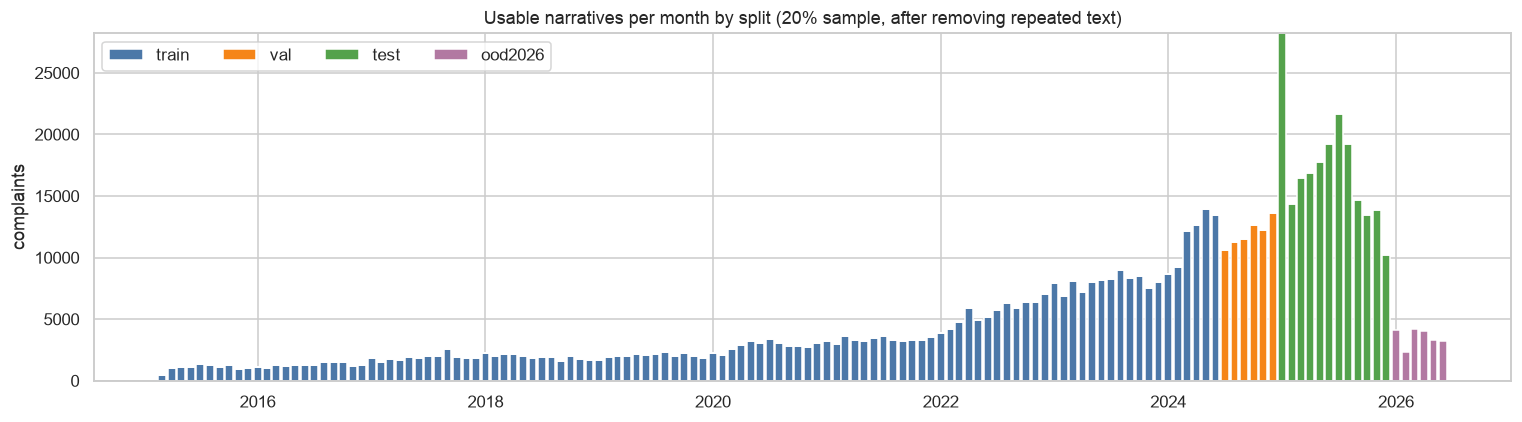

Saved: ['split_train.parquet', 'split_val.parquet', 'split_test.parquet', 'split_ood2026.parquet']


In [6]:
fig, ax = plt.subplots(figsize=(14, 4))
monthly = (df[df["split"].isin(["train", "val", "test", "ood2026"])]
           .groupby([df["date_received"].dt.to_period("M"), "split"]).size().unstack(fill_value=0))
monthly = monthly[["train", "val", "test", "ood2026"]]
monthly.index = monthly.index.to_timestamp()
colors = {"train": "#4C78A8", "val": "#F58518", "test": "#54A24B", "ood2026": "#B279A2"}
bottom = np.zeros(len(monthly))
for s in monthly.columns:
    ax.bar(monthly.index, monthly[s], width=25, bottom=bottom, color=colors[s], label=s)
    bottom += monthly[s].to_numpy()
ax.set_title("Usable narratives per month by split (20% sample, after removing repeated text)")
ax.set_ylabel("complaints")
ax.legend(ncol=4)
savefig("21_split_timeline")

# Save the splits (local only: data/processed is git-ignored)
SPLIT_COLS = [c for c in df.columns if c != "company_response"] + ["company_response"]
for s in ["train", "val", "test", "ood2026"]:
    df.loc[df["split"] == s, SPLIT_COLS].to_parquet(PROCESSED_DIR / f"split_{s}.parquet", index=False)
print("Saved:", [f"split_{s}.parquet" for s in ["train", "val", "test", "ood2026"]])

train = df[df["split"] == "train"].reset_index(drop=True)
val = df[df["split"] == "val"].reset_index(drop=True)
test = df[df["split"] == "test"].reset_index(drop=True)
ood = df[df["split"] == "ood2026"].reset_index(drop=True)
del df
if DEV_FRAC:
    train, val, test, ood = (f.sample(frac=DEV_FRAC, random_state=RANDOM_STATE).reset_index(drop=True) for f in (train, val, test, ood))

## 5. Pre-processing: what each step does and when it applies
All of these steps learn something from the data (a vocabulary, a list of categories, a mean and a standard deviation). They are wrapped in a scikit-learn `ColumnTransformer` / `Pipeline` and **fitted on the training split only**. Validation and test are only ever passed through `.transform()`, so no statistic from a later period leaks backwards.

| Step | Applied to | When it is needed | Choice here |
|---|---|---|---|
| **One-hot (dummy) encoding** | Nominal categories: `company`, `issue`, `sub_product`, `sub_issue`, `state`, `zip3`, `product_clean` | Any model that needs numbers and must not assume an order between categories. Linear models need it; tree models can use it too | `OneHotEncoder(min_frequency=…)`. Levels with fewer training rows than the threshold are lumped into one *infrequent* column, and categories never seen in training map to it as well (`handle_unknown="infrequent_if_exist"`). This bounds the width for high-cardinality columns (4.5k companies, 877 ZIP prefixes) and makes new companies in 2025 safe |
| **Binary flags** | `is_older_american`, `is_servicemember` | Already 0/1, so no encoding is needed | Passed through unchanged |
| **Log transform + standardisation** | Text-shape counts: word count, `$` amounts, `!` count, redaction share, capitals share | Features on very different scales. Regularised linear models (L2 penalty) need comparable scales so the penalty treats them fairly. **Tree models do not need scaling**: splits are invariant to monotone transforms | `log1p` on the heavily skewed counts (skew of 6–55 in notebook 01), then `StandardScaler` (mean 0, sd 1) inside the pipeline |
| **TF-IDF** | `narrative` | Turning free text into numbers for linear and tree models. Sub-linear term frequency stops very long narratives from dominating, and IDF down-weights words that appear everywhere | Words and word pairs (1–2-grams), `min_df=5`, `max_df=0.5`, the 100k most frequent terms, redaction tokens (`XXXX`) excluded by the token pattern. Rows are L2-normalised, so TF-IDF columns are already on a common scale |
| **Feature selection (χ²)** | TF-IDF + one-hot + (unscaled) numeric columns, for LightGBM only | Tree boosting on 100k+ sparse columns is slow on a laptop; most columns are rare | `SelectKBest(chi2, k=20,000)` fitted on train inside the pipeline |
| **Class imbalance** | Both tasks | Credit reporting is about two thirds of narratives (routing), and relief is about 4% positive | `class_weight="balanced"` is tested against no weighting on validation, and the better one is kept. No resampling, so the predicted scores stay usable for ranking |

**Leakage control.** Features are restricted to what is known when the complaint is filed. Post-outcome fields are not loaded (section 1). `date_received` / `year` are *not* used as features either, because the test year lies outside the training range. The model would then have to extrapolate a time trend instead of learning from the complaint. For routing, `issue`, `sub_issue` and `sub_product` are **excluded**: they are chosen in the same form step as the product and sit below it in the taxonomy (Cramér's V with product 0.72–0.87 in notebook 01), so they would give the answer away. For relief they are legitimate inputs.

In [7]:
# Row-wise feature preparation: deterministic per-row transforms with no fitted parameters,
# so they can be applied to every split before the pipeline without any leakage.
NUM_FEATURES = ["log_words", "log_dollar", "log_exclaim", "xxxx_share", "upper_share"]
FLAG_FEATURES = ["is_older_american", "is_servicemember"]


def add_row_features(frame):
    frame["log_words"] = np.log1p(frame["word_count"]).astype("float32")
    frame["log_dollar"] = np.log1p(frame["n_dollar"].fillna(0)).astype("float32")
    frame["log_exclaim"] = np.log1p(frame["n_exclaim"].fillna(0)).astype("float32")
    frame["xxxx_share"] = frame["xxxx_share"].fillna(0).astype("float32")
    frame["upper_share"] = frame["upper_share"].fillna(0).astype("float32")
    return frame


for frame in (train, val, test, ood):
    add_row_features(frame)

ROUTING_CAT = ["company", "state", "zip3"]
RELIEF_CAT = ["product_clean", "issue", "sub_product", "sub_issue", "company", "state", "zip3"]
MIN_FREQUENCY = 30          # a category level needs at least 30 training rows to get its own column


def make_preprocessor(cat_cols, text=True, numeric=True, scale=True):
    """ColumnTransformer: TF-IDF for the narrative, one-hot for categoricals, pass-through flags, numerics
    (standardised for linear models; passed through unscaled for tree models, which do not need scaling)."""
    parts = []
    if text:
        parts.append(("text", make_tfidf(), "narrative"))
    if cat_cols:
        parts.append(("cat", OneHotEncoder(min_frequency=MIN_FREQUENCY, handle_unknown="infrequent_if_exist",
                                           dtype=np.float32), cat_cols))
    parts.append(("flags", "passthrough", FLAG_FEATURES))
    if numeric:
        parts.append(("num", StandardScaler() if scale else "passthrough", NUM_FEATURES))
    return ColumnTransformer(parts, sparse_threshold=1.0)     # always return a sparse matrix


# Redaction tokens: the token pattern keeps alphabetic tokens of 2+ letters, so "XXXX" would survive as the word "xxxx".
# They are removed through a stop-word list that contains nothing else, so that words like "not" and "never" stay.
REDACTION_STOP = ["xx", "xxx", "xxxx", "xxxxx", "xxxxxx", "xxxxxxxx"]


def make_tfidf():
    return TfidfVectorizer(token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b", stop_words=REDACTION_STOP,
                           lowercase=True, ngram_range=(1, 2), min_df=5, max_df=0.5, max_features=100_000,
                           sublinear_tf=True, dtype=np.float32)


print("Row-wise numeric features:", NUM_FEATURES)
display(train[NUM_FEATURES].describe().T[["mean", "std", "min", "max"]])

Row-wise numeric features: ['log_words', 'log_dollar', 'log_exclaim', 'xxxx_share', 'upper_share']


,mean,std,min,max
log_words,4.7859,0.9156,2.3979,8.7037
log_dollar,0.2969,0.5954,0.0000,5.9428
log_exclaim,0.0920,0.3519,0.0000,5.9108
xxxx_share,0.0755,0.1159,0.0000,0.9899
upper_share,0.1030,0.1349,0.0000,0.8765


### 5.1 Fit the pre-processors on the training split and inspect them
Three feature sets are fitted, once each, on the training rows of their task. The fitted matrices are reused by every model of that task, so the expensive TF-IDF fit happens only once per feature set.
- **Routing, structured only:** company, state, ZIP prefix and tag flags (the form fields known at filing, other than the product itself).
- **Routing, text + structured:** the above plus TF-IDF and the scaled text-shape features. *Text-only* models use just the TF-IDF block of this matrix.
- **Relief, text + structured:** product, issue, sub-product, sub-issue, company, state, ZIP prefix, flags, TF-IDF and the text-shape features. *Structured-only* relief models use just the one-hot and flag blocks.

In [8]:
def fit_transform_sets(pre, fit_frame, frames):
    """Fit `pre` on fit_frame only, then transform each frame in `frames` (dict name -> DataFrame)."""
    with Timer() as t:
        X_fit = pre.fit_transform(fit_frame)
    out = {"train": X_fit.tocsr().astype(np.float32)}
    for name, frame in frames.items():
        out[name] = pre.transform(frame).tocsr().astype(np.float32)
    print(f"  fitted in {t.seconds:,.0f}s | " + " | ".join(f"{k}: {v.shape[0]:,} x {v.shape[1]:,}" for k, v in out.items()))
    return out


def block_columns(pre, names):
    """Column indices of the named ColumnTransformer blocks (e.g. only the text block)."""
    idx = [np.arange(pre.output_indices_[n].start, pre.output_indices_[n].stop) for n in names if n in pre.output_indices_]
    return np.concatenate(idx)


def tree_matrix(X, pre, frame):
    """Same columns as X, but with the numeric block unscaled (what make_preprocessor(..., scale=False) produces).
    Trees do not need scaling, and the chi2 filter needs non-negative inputs (log counts and shares are >= 0)."""
    keep = block_columns(pre, ["text", "cat", "flags"])
    return sp.hstack([X[:, keep], sp.csr_matrix(frame[NUM_FEATURES].to_numpy(np.float32))]).tocsr()


# Routing uses every usable narrative
y_route = {s: f["product_clean"].to_numpy() for s, f in [("train", train), ("val", val), ("test", test), ("ood", ood)]}
print("Routing, text + structured:")
pre_route = make_preprocessor(ROUTING_CAT)
X_route = fit_transform_sets(pre_route, train, {"val": val})
cols_route_text = block_columns(pre_route, ["text"])
cols_route_struct = block_columns(pre_route, ["cat", "flags"])

# Relief uses only rows with a defined relief label (monetary relief vs explanation)
rel = {s: f[f["relief"].notna()].reset_index(drop=True) for s, f in [("train", train), ("val", val), ("test", test), ("ood", ood)]}
y_rel = {s: f["relief"].astype(int).to_numpy() for s, f in rel.items()}
print("Relief, text + structured:")
pre_rel = make_preprocessor(RELIEF_CAT)
X_rel = fit_transform_sets(pre_rel, rel["train"], {"val": rel["val"]})
cols_rel_struct = block_columns(pre_rel, ["cat", "flags"])

# What did the encoders learn? (one-hot width per column after min-frequency lumping, TF-IDF vocabulary, scaler)
ohe = pre_rel.named_transformers_["cat"]
enc_summary = pd.DataFrame({
    "levels_in_train": [train.loc[train["relief"].notna(), c].nunique() for c in RELIEF_CAT],
    "one_hot_columns": [len(cats) - (0 if inf is None else len(inf)) + (0 if inf is None else 1)
                        for cats, inf in zip(ohe.categories_, ohe.infrequent_categories_)],
}, index=RELIEF_CAT)
display(enc_summary)
vocab = pre_rel.named_transformers_["text"].vocabulary_
print(f"TF-IDF vocabulary: {len(vocab):,} terms (uni- and bigrams), e.g. {sorted(vocab, key=vocab.get)[:8]}")
scaler = pre_rel.named_transformers_["num"]
display(pd.DataFrame({"train_mean": scaler.mean_, "train_sd": scaler.scale_}, index=NUM_FEATURES))

Routing, text + structured:


  fitted in 33s | train: 404,004 x 101,337 | val: 71,822 x 101,337
Relief, text + structured:


  fitted in 27s | train: 297,530 x 101,696 | val: 43,244 x 101,696


,levels_in_train,one_hot_columns
product_clean,11,11
issue,171,125
sub_product,85,68
sub_issue,264,209
company,3687,506
state,63,58
zip3,876,712


TF-IDF vocabulary: 100,000 terms (uni- and bigrams), e.g. ['aa', 'aadvantage', 'aafes', 'aag', 'aargon', 'aargon agency', 'aargon collection', 'ab']


,train_mean,train_sd
log_words,4.8157,0.9214
log_dollar,0.3285,0.6135
log_exclaim,0.0990,0.3652
xxxx_share,0.0668,0.1008
upper_share,0.0963,0.1286


## 6. Evaluation helpers
- **Routing:** macro-F1 (every product counts equally, so small products are not hidden by credit reporting), plus weighted F1 and accuracy for context.
- **Relief:** average precision (AP, the area under the precision–recall curve; a random ranking scores the base rate), **precision in the top 10%** of complaints ranked by predicted relief (what a review queue would see), its *lift* over the base rate, and ROC-AUC as a secondary measure.

Every model is recorded in one results table. **Selection uses validation only.**

In [9]:
RESULTS = []


def precision_at_frac(y, score, frac=0.10):
    """Precision among the top `frac` of rows ranked by score (ties broken by a fixed random order)."""
    y = np.asarray(y)
    rng = np.random.default_rng(RANDOM_STATE)
    order = np.lexsort((rng.random(len(y)), -np.asarray(score)))
    k = max(1, int(np.ceil(frac * len(y))))
    return float(y[order[:k]].mean())


def relief_scores(y, s):
    base = float(np.mean(y))
    p10 = precision_at_frac(y, s, 0.10)
    return {"AP": average_precision_score(y, s), "P@10%": p10, "lift@10%": p10 / base, "ROC_AUC": roc_auc_score(y, s),
            "base_rate": base, "n": len(y), "positives": int(np.sum(y))}


def routing_scores(y, pred):
    return {"macro_F1": f1_score(y, pred, average="macro"), "weighted_F1": f1_score(y, pred, average="weighted"),
            "accuracy": accuracy_score(y, pred), "n": len(y)}


def record(task, model, features, split, metrics, params="", fit_s=np.nan):
    RESULTS.append({"task": task, "model": model, "features": features, "split": split, **metrics,
                    "params": params, "fit_seconds": round(fit_s, 1)})


def results_frame(task, split="val"):
    r = pd.DataFrame(RESULTS)
    r = r[(r["task"] == task) & (r["split"] == split)].dropna(axis=1, how="all")
    return r.drop(columns=["task", "split"])

## 7. Routing models (product, 11 classes)
Five models, from trivial to strongest:
1. **Majority class.** Always predicts the most common product (credit reporting). This is the floor that the proposal's criterion refers to.
2. **Structured-only logistic regression.** Company, state, ZIP prefix and tags, with no text. It measures how much the form alone says about the product.
3. **TF-IDF + logistic regression (text only).** The linear text model named in the proposal.
4. **TF-IDF + structured logistic regression.** Does the company add to the text?
5. **LightGBM** on the χ²-selected TF-IDF and one-hot features plus the scaled numerics. A non-linear model that can capture interactions (for example, a given company *and* a given word).

Hyper-parameters are tuned on validation macro-F1: the inverse regularisation strength `C` and the class weighting for the linear models, and the tree size for LightGBM (the number of trees is set by early stopping on validation).

In [10]:
# 1. Majority class
dummy_route = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(y_route["train"]), 1)), y_route["train"])
record("routing", "Majority class", "none", "val", routing_scores(y_route["val"], dummy_route.predict(np.zeros((len(val), 1)))))
print("Majority class:", dummy_route.classes_[np.argmax(dummy_route.class_prior_)])


def tune_logreg(task, name, features, Xtr, ytr, Xva, yva, grid, scorer):
    """Fit one logistic regression per grid point on train, score on validation; return the best fitted model."""
    best = None
    for params in grid:
        with Timer() as t:
            model = LogisticRegression(max_iter=300, tol=1e-3, random_state=RANDOM_STATE, **params).fit(Xtr, ytr)
        metrics = scorer(model, Xva, yva)
        record(task, name, features, "val", metrics, params=str(params), fit_s=t.seconds)
        key = metrics["macro_F1"] if task == "routing" else metrics["AP"]
        print(f"  {params}: {('macro-F1' if task == 'routing' else 'AP')} = {key:.4f}  ({t.seconds:,.0f}s)")
        if best is None or key > best[0]:
            best = (key, params, model)
    return best


route_scorer = lambda model, X, y: routing_scores(y, model.predict(X))
GRID_LR = [{"C": 2.0, "class_weight": None}, {"C": 8.0, "class_weight": None}, {"C": 8.0, "class_weight": "balanced"}]

print("2. Structured-only logistic regression")
best_route_struct = tune_logreg("routing", "Structured-only LogReg", "company, state, zip3, tags",
                                X_route["train"][:, cols_route_struct], y_route["train"],
                                X_route["val"][:, cols_route_struct], y_route["val"], GRID_LR, route_scorer)
print("3. TF-IDF logistic regression (text only)")
best_route_text = tune_logreg("routing", "TF-IDF LogReg", "narrative",
                              X_route["train"][:, cols_route_text], y_route["train"],
                              X_route["val"][:, cols_route_text], y_route["val"], GRID_LR, route_scorer)
print("4. TF-IDF + structured logistic regression")
best_route_both = tune_logreg("routing", "TF-IDF + structured LogReg", "narrative + company, state, zip3, tags, text shape",
                              X_route["train"], y_route["train"], X_route["val"], y_route["val"], GRID_LR, route_scorer)

Majority class: Credit reporting
2. Structured-only logistic regression


  {'C': 2.0, 'class_weight': None}: macro-F1 = 0.5336  (3s)


  {'C': 8.0, 'class_weight': None}: macro-F1 = 0.5570  (3s)


  {'C': 8.0, 'class_weight': 'balanced'}: macro-F1 = 0.5330  (4s)
3. TF-IDF logistic regression (text only)


  {'C': 2.0, 'class_weight': None}: macro-F1 = 0.6675  (82s)


  {'C': 8.0, 'class_weight': None}: macro-F1 = 0.6788  (91s)


  {'C': 8.0, 'class_weight': 'balanced'}: macro-F1 = 0.6594  (90s)
4. TF-IDF + structured logistic regression


  {'C': 2.0, 'class_weight': None}: macro-F1 = 0.7333  (112s)


  {'C': 8.0, 'class_weight': None}: macro-F1 = 0.7236  (84s)


  {'C': 8.0, 'class_weight': 'balanced'}: macro-F1 = 0.6948  (144s)


**LightGBM (routing).** Gradient boosting on 400k rows × 100k sparse columns × 11 classes would take hours on a laptop. So the χ² filter keeps the 20,000 most class-informative columns, and the trees are trained on a **stratified random 150,000-row subsample of the training split** (documented sampling; the linear models use all training rows). Early stopping on validation multi-class log-loss picks the number of trees. Only one tree size is tried, because each fit takes 7–8 minutes. Class weighting is off, because the linear models showed that balanced weights *lower* validation macro-F1 for this task.

In [11]:
LGBM_SUBSAMPLE = 150_000
LGBM_K = 20_000


def stratified_subsample(y, n, seed=RANDOM_STATE):
    """Row indices of a stratified random subsample (class shares preserved)."""
    if n >= len(y):
        return np.arange(len(y))
    rng = np.random.default_rng(seed)
    y = np.asarray(y)
    idx = []
    for cls in np.unique(y):
        members = np.flatnonzero(y == cls)
        take = max(1, int(round(n * len(members) / len(y))))
        idx.append(rng.choice(members, size=min(take, len(members)), replace=False))
    return np.sort(np.concatenate(idx))


sub_route = stratified_subsample(y_route["train"], LGBM_SUBSAMPLE)
Xt_route_tr = tree_matrix(X_route["train"][sub_route], pre_route, train.iloc[sub_route])
Xt_route_va = tree_matrix(X_route["val"], pre_route, val)
with Timer() as t:
    selector_route = SelectKBest(chi2, k=LGBM_K).fit(Xt_route_tr, y_route["train"][sub_route])
Xs_route_tr, Xs_route_va = selector_route.transform(Xt_route_tr), selector_route.transform(Xt_route_va)
del Xt_route_tr, Xt_route_va
print(f"chi2 selection: {X_route['train'].shape[1]:,} -> {Xs_route_tr.shape[1]:,} columns ({t.seconds:,.0f}s)")

best_route_lgbm = None
for params in [{"num_leaves": 63, "class_weight": None}]:      # one tree size (7-8 min per fit); trees chosen by early stopping
    with Timer() as t:
        g = lgb.LGBMClassifier(n_estimators=1500, learning_rate=0.1, min_child_samples=20, colsample_bytree=0.3,
                               subsample=0.8, subsample_freq=1, reg_lambda=1.0, random_state=RANDOM_STATE,
                               n_jobs=N_JOBS, verbose=-1, **params)
        g.fit(Xs_route_tr, y_route["train"][sub_route], eval_set=[(Xs_route_va, y_route["val"])],
              callbacks=[lgb.early_stopping(30, verbose=False)])
    metrics = routing_scores(y_route["val"], g.predict(Xs_route_va))
    params = {**params, "n_estimators": int(g.best_iteration_)}
    record("routing", "LightGBM", f"chi2 top {LGBM_K:,} of text + structured, {LGBM_SUBSAMPLE:,}-row subsample",
           "val", metrics, params=str(params), fit_s=t.seconds)
    print(f"  {params}: macro-F1 = {metrics['macro_F1']:.4f} ({t.seconds:,.0f}s)")
    if best_route_lgbm is None or metrics["macro_F1"] > best_route_lgbm[0]:
        best_route_lgbm = (metrics["macro_F1"], params, g)

display(results_frame("routing").sort_values("macro_F1", ascending=False))

chi2 selection: 101,337 -> 20,000 columns (0s)


  {'num_leaves': 63, 'class_weight': None, 'n_estimators': 93}: macro-F1 = 0.7134 (221s)


,model,features,macro_F1,weighted_F1,accuracy,n,params,fit_seconds
7,TF-IDF + structured LogReg,"narrative + company, state, zip3, tags, text shape",0.7333,0.9185,0.9200,71822,"{'C': 2.0, 'class_weight': None}",111.7000
8,TF-IDF + structured LogReg,"narrative + company, state, zip3, tags, text shape",0.7236,0.9165,0.9181,71822,"{'C': 8.0, 'class_weight': None}",84.5000
10,LightGBM,"chi2 top 20,000 of text + structured, 150,000-row subsample",0.7134,0.9149,0.9170,71822,"{'num_leaves': 63, 'class_weight': None, 'n_estimators': 93}",221.5000
9,TF-IDF + structured LogReg,"narrative + company, state, zip3, tags, text shape",0.6948,0.8978,0.8908,71822,"{'C': 8.0, 'class_weight': 'balanced'}",143.6000
5,TF-IDF LogReg,narrative,0.6788,0.9007,0.9040,71822,"{'C': 8.0, 'class_weight': None}",91.1000
4,TF-IDF LogReg,narrative,0.6675,0.8994,0.9030,71822,"{'C': 2.0, 'class_weight': None}",82.4000
6,TF-IDF LogReg,narrative,0.6594,0.8680,0.8570,71822,"{'C': 8.0, 'class_weight': 'balanced'}",90.4000
2,Structured-only LogReg,"company, state, zip3, tags",0.5570,0.8622,0.8603,71822,"{'C': 8.0, 'class_weight': None}",3.5000
1,Structured-only LogReg,"company, state, zip3, tags",0.5336,0.8612,0.8596,71822,"{'C': 2.0, 'class_weight': None}",2.9000
3,Structured-only LogReg,"company, state, zip3, tags",0.5330,0.8390,0.8071,71822,"{'C': 8.0, 'class_weight': 'balanced'}",4.3000


**Routing results on validation (2024 H2)**
- Every model clears the majority-class floor (macro-F1 0.08) by a wide margin.
- **The form alone** (company, state, ZIP prefix, tags) reaches 0.56. Many companies serve a single product, for example Equifax → credit reporting and Navient → student loans.
- **The narrative alone** reaches 0.68. **Narrative + form** is best at **0.73**, so the two sources complement each other.
- **LightGBM (0.71)** does not beat the linear model. On sparse TF-IDF features a well-regularised linear model is hard to beat. LightGBM also saw only 150k rows and 20k columns, versus 404k rows and 101k columns for the logistic regression.
- **Balanced class weights lowered macro-F1 in every model** (for example 0.695 vs 0.724 for text + structured at C = 8). The weights raise recall for the small products but cost more precision than they gain, because those products share vocabulary with the large ones. The unweighted models are kept.

### 7.1 Secondary routing target: `issue`
Issue labels drifted with the CFPB form, like the product labels. The task is restricted to issues with **at least 200 training rows that also occur in validation**. Rows with any other issue are left out of this task (the count is printed). The issue model receives the narrative plus company, state and ZIP prefix, the same inputs as product routing. Two models are compared: majority class and TF-IDF + structured logistic regression, using the routing matrix (no new fitting of encoders). The regularisation strength is the best one from product routing, and the fit uses a stratified 150k-row subsample of the training rows, to save compute.

In [12]:
issue_counts = train["issue"].value_counts()
ISSUE_LABELS = sorted(set(issue_counts[issue_counts >= 200].index) & set(val["issue"]))
in_issue = {s: f["issue"].isin(ISSUE_LABELS).to_numpy() for s, f in [("train", train), ("val", val), ("test", test)]}
print(f"Issue classes kept: {len(ISSUE_LABELS)} of {train['issue'].nunique()} in train | rows kept: "
      + ", ".join(f"{s} {m.mean():.1%}" for s, m in in_issue.items()))
y_issue = {s: f["issue"].to_numpy()[in_issue[s]] for s, f in [("train", train), ("val", val), ("test", test)]}

dummy_issue = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(y_issue["train"]), 1)), y_issue["train"])
record("issue", "Majority class", "none", "val", routing_scores(y_issue["val"], dummy_issue.predict(np.zeros((len(y_issue["val"]), 1)))))
issue_params = {k: v for k, v in best_route_both[1].items()}
# 80+ classes make the multinomial fit about 8x slower than product routing, so it uses a stratified 150k-row subsample of train
issue_sub = stratified_subsample(y_issue["train"], 150_000)
with Timer() as t:
    issue_lr = LogisticRegression(max_iter=300, tol=1e-3, random_state=RANDOM_STATE, **issue_params).fit(
        X_route["train"][in_issue["train"]][issue_sub], y_issue["train"][issue_sub])
record("issue", "TF-IDF + structured LogReg", "narrative + company, state, zip3, tags, text shape", "val",
       routing_scores(y_issue["val"], issue_lr.predict(X_route["val"][in_issue["val"]])), params=str(issue_params), fit_s=t.seconds)
display(results_frame("issue"))

Issue classes kept: 55 of 171 in train | rows kept: train 79.9%, val 99.2%, test 99.1%


,model,features,macro_F1,weighted_F1,accuracy,n,params,fit_seconds
11,Majority class,none,0.0104,0.2274,0.3988,71264,,NaN
12,TF-IDF + structured LogReg,"narrative + company, state, zip3, tags, text shape",0.3477,0.5923,0.6098,71264,"{'C': 2.0, 'class_weight': None}",225.5000


**Issue routing (secondary).** 55 issue labels have at least 200 training rows and also occur in validation. Together they cover 99% of validation and test rows. Macro-F1 is **0.35 on validation**, against 0.01 for the majority class: far above the floor, but weak in absolute terms. The labels overlap heavily, for example *"Incorrect information on your report"* (current form) vs *"Incorrect information on credit report"* (pre-2017 form), and *"Problem with a company's investigation…"* vs *"Problem with a credit reporting company's investigation…"*. A model cannot separate labels that mean the same thing. Harmonising `issue` the way notebook 01 harmonised `product` is the first thing to do before issue routing is worth tuning further.

## 8. Relief models (monetary relief vs explanation)
Five models. Two of them use **only the structured form fields**, which is the comparison the proposal asks for ("does the narrative add information beyond what the complaint form already records?"):
1. **Base rate (random ranking).** AP equals the positive rate. It is the floor.
2. **Structured-only logistic regression.** Product, issue, sub-product, sub-issue, company, state, ZIP prefix and tags, one-hot encoded.
3. **Structured-only LightGBM.** The proposal's "gradient boosting on the structured fields", with the same columns. Trees can combine company × issue interactions that a linear model cannot.
4. **TF-IDF + structured logistic regression.** The same structured columns plus the narrative and its text-shape features.
5. **LightGBM on text + structured.** χ²-selected TF-IDF (20k columns) plus all structured and numeric columns.

Selection metric: validation **average precision**. Class weighting is tuned like any other setting. AP and top-decile precision only depend on the *ranking*, so weighting matters less here than for routing.

In [13]:
relief_scorer = lambda model, X, y: relief_scores(y, model.predict_proba(X)[:, 1])
rng = np.random.default_rng(RANDOM_STATE)
record("relief", "Base rate (random ranking)", "none", "val", relief_scores(y_rel["val"], rng.random(len(y_rel["val"]))))

GRID_LR_REL = [{"C": c, "class_weight": w} for w in ("balanced", None) for c in (0.25, 1.0, 4.0)]
print("2. Structured-only logistic regression")
best_rel_struct = tune_logreg("relief", "Structured-only LogReg", "product, issue, sub-product, sub-issue, company, state, zip3, tags",
                              X_rel["train"][:, cols_rel_struct], y_rel["train"], X_rel["val"][:, cols_rel_struct], y_rel["val"],
                              GRID_LR_REL, relief_scorer)
print("4. TF-IDF + structured logistic regression")
best_rel_both = tune_logreg("relief", "TF-IDF + structured LogReg", "narrative + all structured + text shape",
                            X_rel["train"], y_rel["train"], X_rel["val"], y_rel["val"], GRID_LR_REL, relief_scorer)

2. Structured-only logistic regression


  {'C': 0.25, 'class_weight': 'balanced'}: AP = 0.3414  (0s)


  {'C': 1.0, 'class_weight': 'balanced'}: AP = 0.3385  (0s)


  {'C': 4.0, 'class_weight': 'balanced'}: AP = 0.3385  (0s)


  {'C': 0.25, 'class_weight': None}: AP = 0.3560  (0s)
  {'C': 1.0, 'class_weight': None}: AP = 0.3540  (0s)


  {'C': 4.0, 'class_weight': None}: AP = 0.3536  (0s)
4. TF-IDF + structured logistic regression


... (2 outputs left out)

  {'C': 4.0, 'class_weight': 'balanced'}: AP = 0.3912  (46s)


  {'C': 0.25, 'class_weight': None}: AP = 0.3731  (12s)


  {'C': 1.0, 'class_weight': None}: AP = 0.3724  (12s)


  {'C': 4.0, 'class_weight': None}: AP = 0.3722  (11s)


In [14]:
def tune_lgbm_relief(name, features, Xtr, ytr, Xva, yva, grid):
    best = None
    for params in grid:
        with Timer() as t:
            g = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.1, min_child_samples=50, colsample_bytree=0.3,
                                   subsample=0.8, subsample_freq=1, reg_lambda=1.0, metric="average_precision",
                                   random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=-1, **params)
            g.fit(Xtr, ytr, eval_set=[(Xva, yva)], callbacks=[lgb.early_stopping(50, verbose=False)])
        metrics = relief_scores(yva, g.predict_proba(Xva)[:, 1])
        params = {**params, "n_estimators": int(g.best_iteration_)}
        record("relief", name, features, "val", metrics, params=str(params), fit_s=t.seconds)
        print(f"  {params}: AP = {metrics['AP']:.4f} ({t.seconds:,.0f}s)")
        if best is None or metrics["AP"] > best[0]:
            best = (metrics["AP"], params, g)
    return best


GRID_LGBM_REL = [{"num_leaves": 31, "is_unbalance": False}, {"num_leaves": 31, "is_unbalance": True}]   # weighting on/off
print("3. Structured-only LightGBM")
best_rel_struct_lgbm = tune_lgbm_relief("Structured-only LightGBM", "product, issue, sub-product, sub-issue, company, state, zip3, tags",
                                        X_rel["train"][:, cols_rel_struct], y_rel["train"],
                                        X_rel["val"][:, cols_rel_struct], y_rel["val"], GRID_LGBM_REL)

print("5. LightGBM on text + structured (chi2 top 20k of TF-IDF + one-hot, plus numerics)")
Xt_rel_tr, Xt_rel_va = tree_matrix(X_rel["train"], pre_rel, rel["train"]), tree_matrix(X_rel["val"], pre_rel, rel["val"])
with Timer() as t:
    selector_rel = SelectKBest(chi2, k=LGBM_K).fit(Xt_rel_tr, y_rel["train"])
Xs_rel_tr, Xs_rel_va = selector_rel.transform(Xt_rel_tr), selector_rel.transform(Xt_rel_va)
del Xt_rel_tr, Xt_rel_va
print(f"  chi2 selection: {X_rel['train'].shape[1]:,} -> {Xs_rel_tr.shape[1]:,} columns ({t.seconds:,.0f}s); trained on all {Xs_rel_tr.shape[0]:,} relief rows")
best_rel_lgbm = tune_lgbm_relief("LightGBM", f"chi2 top {LGBM_K:,} of text + structured + text shape",
                                 Xs_rel_tr, y_rel["train"], Xs_rel_va, y_rel["val"], GRID_LGBM_REL)

display(results_frame("relief").sort_values("AP", ascending=False))

3. Structured-only LightGBM


  {'num_leaves': 31, 'is_unbalance': False, 'n_estimators': 137}: AP = 0.3841 (8s)


  {'num_leaves': 31, 'is_unbalance': True, 'n_estimators': 139}: AP = 0.3856 (2s)
5. LightGBM on text + structured (chi2 top 20k of TF-IDF + one-hot, plus numerics)


  chi2 selection: 101,696 -> 20,000 columns (0s); trained on all 297,530 relief rows


  {'num_leaves': 31, 'is_unbalance': False, 'n_estimators': 143}: AP = 0.4057 (59s)


  {'num_leaves': 31, 'is_unbalance': True, 'n_estimators': 160}: AP = 0.4023 (42s)


,model,features,n,params,fit_seconds,AP,P@10%,lift@10%,ROC_AUC,base_rate,positives
28,LightGBM,"chi2 top 20,000 of text + structured + text shape",43244,"{'num_leaves': 31, 'is_unbalance': False, 'n_estimators': 143}",58.6000,0.4057,0.2694,8.3681,0.9584,0.0322,"1,392.0000"
29,LightGBM,"chi2 top 20,000 of text + structured + text shape",43244,"{'num_leaves': 31, 'is_unbalance': True, 'n_estimators': 160}",41.8000,0.4023,0.2714,8.4327,0.9587,0.0322,"1,392.0000"
20,TF-IDF + structured LogReg,narrative + all structured + text shape,43244,"{'C': 0.25, 'class_weight': 'balanced'}",8.2000,0.3971,0.2701,8.3896,0.9597,0.0322,"1,392.0000"
22,TF-IDF + structured LogReg,narrative + all structured + text shape,43244,"{'C': 4.0, 'class_weight': 'balanced'}",45.5000,0.3912,0.2708,8.4112,0.9596,0.0322,"1,392.0000"
21,TF-IDF + structured LogReg,narrative + all structured + text shape,43244,"{'C': 1.0, 'class_weight': 'balanced'}",59.7000,0.3884,0.2701,8.3896,0.9589,0.0322,"1,392.0000"
27,Structured-only LightGBM,"product, issue, sub-product, sub-issue, company, state, zip3, tags",43244,"{'num_leaves': 31, 'is_unbalance': True, 'n_estimators': 139}",2.4000,0.3856,0.2587,8.0377,0.9553,0.0322,"1,392.0000"
26,Structured-only LightGBM,"product, issue, sub-product, sub-issue, company, state, zip3, tags",43244,"{'num_leaves': 31, 'is_unbalance': False, 'n_estimators': 137}",8.2000,0.3841,0.2569,7.9802,0.9544,0.0322,"1,392.0000"
23,TF-IDF + structured LogReg,narrative + all structured + text shape,43244,"{'C': 0.25, 'class_weight': None}",11.8000,0.3731,0.2592,8.0520,0.9523,0.0322,"1,392.0000"
24,TF-IDF + structured LogReg,narrative + all structured + text shape,43244,"{'C': 1.0, 'class_weight': None}",12.1000,0.3724,0.2587,8.0377,0.9522,0.0322,"1,392.0000"
25,TF-IDF + structured LogReg,narrative + all structured + text shape,43244,"{'C': 4.0, 'class_weight': None}",11.5000,0.3722,0.2587,8.0377,0.9522,0.0322,"1,392.0000"


**Relief results on validation (2024 H2, base rate 3.2%)**
- Every model ranks far better than chance (AP 0.36–0.41 vs 0.03).
- **The structured form fields already carry most of the signal.** Structured-only LightGBM reaches AP 0.386, because product, company and issue largely decide whether money is returned (notebook 01: 0.1% relief for credit reporting vs about 18% for credit cards).
- **Adding the narrative helps, but modestly:** LightGBM on text + structured reaches **0.406** (+0.02 AP), and the text + structured logistic regression reaches 0.397.
- Class weighting helped the logistic regression (0.397 vs 0.373) and made no real difference to LightGBM (0.402 vs 0.406). This is expected: AP depends only on the ranking.
- ROC-AUC is about 0.95–0.96 for every model. It looks excellent only because most negatives are easy (credit-reporting complaints), which is why the proposal uses AP and top-decile precision instead.

## 9. Model comparison on validation and choice of the final models
The table below is the filled-in comparison for both tasks (validation only, best setting per model). The final model for each task is the one with the best validation score: macro-F1 for routing, AP for relief. The structured-only models are kept as the reference that the proposal asks the final relief model to beat.

**Routing (product), validation**

,model,features,macro_F1,weighted_F1,accuracy,params,fit_seconds
0,TF-IDF + structured LogReg,"narrative + company, state, zip3, tags, text shape",0.7333,0.9185,0.9200,"{'C': 2.0, 'class_weight': None}",111.7000
1,LightGBM,"chi2 top 20,000 of text + structured, 150,000-row subsample",0.7134,0.9149,0.9170,"{'num_leaves': 63, 'class_weight': None, 'n_estimators': 93}",221.5000
2,TF-IDF LogReg,narrative,0.6788,0.9007,0.9040,"{'C': 8.0, 'class_weight': None}",91.1000
3,Structured-only LogReg,"company, state, zip3, tags",0.5570,0.8622,0.8603,"{'C': 8.0, 'class_weight': None}",3.5000
4,Majority class,none,0.0788,0.6639,0.7655,,NaN


**Relief, validation**

,model,features,AP,P@10%,lift@10%,ROC_AUC,base_rate,params,fit_seconds
0,LightGBM,"chi2 top 20,000 of text + structured + text shape",0.4057,0.2694,8.3681,0.9584,0.0322,"{'num_leaves': 31, 'is_unbalance': False, 'n_estimators': 143}",58.6000
1,TF-IDF + structured LogReg,narrative + all structured + text shape,0.3971,0.2701,8.3896,0.9597,0.0322,"{'C': 0.25, 'class_weight': 'balanced'}",8.2000
2,Structured-only LightGBM,"product, issue, sub-product, sub-issue, company, state, zip3, tags",0.3856,0.2587,8.0377,0.9553,0.0322,"{'num_leaves': 31, 'is_unbalance': True, 'n_estimators': 139}",2.4000
3,Structured-only LogReg,"product, issue, sub-product, sub-issue, company, state, zip3, tags",0.3560,0.2550,7.9228,0.9496,0.0322,"{'C': 0.25, 'class_weight': None}",0.2000
4,Base rate (random ranking),none,0.0309,0.0317,0.9841,0.4827,0.0322,,NaN


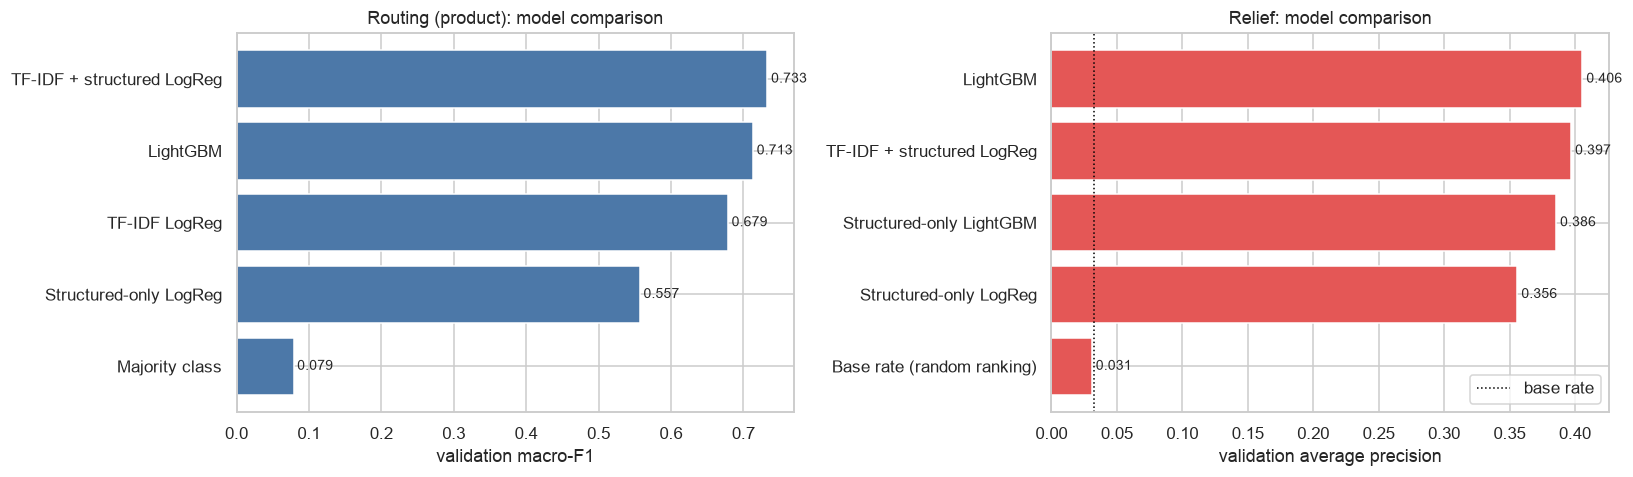

Final routing model: TF-IDF + structured LogReg  {'C': 2.0, 'class_weight': None}  (val macro-F1 0.7333)
Final relief model:  LightGBM  {'num_leaves': 31, 'is_unbalance': False, 'n_estimators': 143}  (val AP 0.4057)


In [15]:
def best_per_model(task, metric):
    r = results_frame(task)
    return r.loc[r.groupby("model")[metric].idxmax()].sort_values(metric, ascending=False).reset_index(drop=True)


cmp_route = best_per_model("routing", "macro_F1")
cmp_issue = best_per_model("issue", "macro_F1")
cmp_rel = best_per_model("relief", "AP")
display(Markdown("**Routing (product), validation**"))
display(cmp_route[["model", "features", "macro_F1", "weighted_F1", "accuracy", "params", "fit_seconds"]])
display(Markdown("**Relief, validation**"))
display(cmp_rel[["model", "features", "AP", "P@10%", "lift@10%", "ROC_AUC", "base_rate", "params", "fit_seconds"]])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].barh(cmp_route["model"][::-1], cmp_route["macro_F1"][::-1], color="#4C78A8")
axes[0].set_xlabel("validation macro-F1")
axes[0].set_title("Routing (product): model comparison")
for i, v in enumerate(cmp_route["macro_F1"][::-1]):
    axes[0].text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9)
axes[1].barh(cmp_rel["model"][::-1], cmp_rel["AP"][::-1], color="#E45756")
axes[1].axvline(cmp_rel["base_rate"].iloc[0], color="black", ls=":", lw=1, label="base rate")
axes[1].set_xlabel("validation average precision")
axes[1].set_title("Relief: model comparison")
for i, v in enumerate(cmp_rel["AP"][::-1]):
    axes[1].text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=9)
axes[1].legend(loc="lower right")
savefig("22_model_comparison_validation")

FINAL_ROUTE = cmp_route.iloc[0]
FINAL_REL = cmp_rel.iloc[0]
print(f"Final routing model: {FINAL_ROUTE['model']}  {FINAL_ROUTE['params']}  (val macro-F1 {FINAL_ROUTE['macro_F1']:.4f})")
print(f"Final relief model:  {FINAL_REL['model']}  {FINAL_REL['params']}  (val AP {FINAL_REL['AP']:.4f})")

**Final model choice (validation only)**
- **Routing → TF-IDF + structured logistic regression** (`C = 2`, unweighted): the best validation macro-F1 (0.733). It is also the fastest of the strong models (90 s) and the easiest to explain.
- **Relief → LightGBM on text + structured** (143 trees, 31 leaves, unweighted): the best validation AP (0.406). The logistic regression is within 0.01 AP and could replace it if interpretability mattered more.
- **Reference for the proposal's criterion → structured-only LightGBM**: the strongest model without the narrative (AP 0.386).

### 9.1 Validation precision–recall curves (relief)
The PR curve shows the trade-off a review team would face. Further right means more of the relief cases are found; higher means fewer wasted reviews.

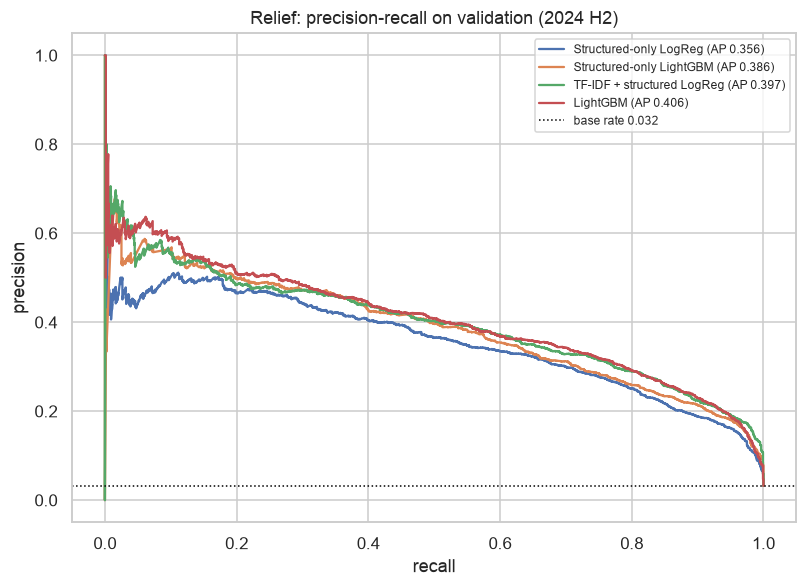

In [16]:
val_scores = {
    "Structured-only LogReg": best_rel_struct[2].predict_proba(X_rel["val"][:, cols_rel_struct])[:, 1],
    "Structured-only LightGBM": best_rel_struct_lgbm[2].predict_proba(X_rel["val"][:, cols_rel_struct])[:, 1],
    "TF-IDF + structured LogReg": best_rel_both[2].predict_proba(X_rel["val"])[:, 1],
    "LightGBM": best_rel_lgbm[2].predict_proba(Xs_rel_va)[:, 1],
}
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for name, s in val_scores.items():
    p, r, _ = precision_recall_curve(y_rel["val"], s)
    ax.plot(r, p, lw=1.5, label=f"{name} (AP {average_precision_score(y_rel['val'], s):.3f})")
ax.axhline(y_rel["val"].mean(), color="black", ls=":", lw=1, label=f"base rate {y_rel['val'].mean():.3f}")
ax.set_xlabel("recall")
ax.set_ylabel("precision")
ax.set_title("Relief: precision-recall on validation (2024 H2)")
ax.legend(fontsize=8)
savefig("23_relief_pr_curves_validation")

## 10. Final models: refit on train + validation, evaluate once on test
Each chosen model is rebuilt as **one scikit-learn `Pipeline`** (pre-processing + feature selection where used + estimator) with the settings selected on validation. It is refitted on train **+ validation**, so it also learns from the most recent pre-test months, which matters because of the time drift. The number of LightGBM trees is the one found by early stopping. The pipeline is then applied to the 2025 test set **once**.

For reference, the majority-class and structured-only baselines are refitted the same way and scored on the same test set. They were not used for any choice. They are needed because the proposal's success criteria are defined *relative* to them on a later period.

In [17]:
trainval = pd.concat([train, val], ignore_index=True)
rel_trainval = trainval[trainval["relief"].notna()].reset_index(drop=True)
y_route_tv = trainval["product_clean"].to_numpy()
y_rel_tv = rel_trainval["relief"].astype(int).to_numpy()


def parse_params(s):
    return ast.literal_eval(s) if s else {}      # params were stored as the repr of a small dict of literals


def build_pipeline(task, row):
    """Recreate the chosen model as a full Pipeline with its validated settings."""
    params = parse_params(row["params"])
    name = row["model"]
    if task == "routing":
        if name == "LightGBM":
            sub = {k: v for k, v in params.items()}
            return Pipeline([("prep", make_preprocessor(ROUTING_CAT, scale=False)), ("select", SelectKBest(chi2, k=LGBM_K)),
                             ("model", lgb.LGBMClassifier(learning_rate=0.1, min_child_samples=20, colsample_bytree=0.3, subsample=0.8,
                                                          subsample_freq=1, reg_lambda=1.0, random_state=RANDOM_STATE, n_jobs=N_JOBS,
                                                          verbose=-1, **sub))])
        text = name != "Structured-only LogReg"
        cats = ROUTING_CAT if name != "TF-IDF LogReg" else []
        pre = make_preprocessor(cats, text=text, numeric=(name == "TF-IDF + structured LogReg"))
        if name == "TF-IDF LogReg":
            pre = ColumnTransformer([("text", make_tfidf(), "narrative")], sparse_threshold=1.0)
        return Pipeline([("prep", pre), ("model", LogisticRegression(max_iter=300, tol=1e-3, random_state=RANDOM_STATE, **params))])
    # relief
    lgbm_kwargs = dict(learning_rate=0.1, metric="average_precision", min_child_samples=50, colsample_bytree=0.3, subsample=0.8, subsample_freq=1,
                       reg_lambda=1.0, random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=-1)
    if name == "LightGBM":
        return Pipeline([("prep", make_preprocessor(RELIEF_CAT, scale=False)), ("select", SelectKBest(chi2, k=LGBM_K)),
                         ("model", lgb.LGBMClassifier(**lgbm_kwargs, **params))])
    if name == "Structured-only LightGBM":
        return Pipeline([("prep", make_preprocessor(RELIEF_CAT, text=False, numeric=False)),
                         ("model", lgb.LGBMClassifier(**lgbm_kwargs, **params))])
    if name == "Structured-only LogReg":
        return Pipeline([("prep", make_preprocessor(RELIEF_CAT, text=False, numeric=False)),
                         ("model", LogisticRegression(max_iter=300, tol=1e-3, random_state=RANDOM_STATE, **params))])
    return Pipeline([("prep", make_preprocessor(RELIEF_CAT)),
                     ("model", LogisticRegression(max_iter=300, tol=1e-3, random_state=RANDOM_STATE, **params))])


def fit_final(task, row, X, y):
    pipe = build_pipeline(task, row)
    if task == "routing" and row["model"] == "LightGBM":      # same documented subsample size as in tuning
        idx = stratified_subsample(y, LGBM_SUBSAMPLE)
        X, y = X.iloc[idx], y[idx]
    with Timer() as t:
        pipe.fit(X, y)
    print(f"  {task}: {row['model']} refitted on {len(y):,} rows in {t.seconds:,.0f}s")
    return pipe, t.seconds


final_route, t_route = fit_final("routing", FINAL_ROUTE, trainval, y_route_tv)
final_rel, t_rel = fit_final("relief", FINAL_REL, rel_trainval, y_rel_tv)

# Reference baselines for the proposal's criteria (refitted the same way; not used for selection)
ref_rel_row = cmp_rel[cmp_rel["model"].str.startswith("Structured-only")].iloc[0]       # best structured-only model on validation
ref_rel, _ = fit_final("relief", ref_rel_row, rel_trainval, y_rel_tv)
ref_route_row = cmp_route[cmp_route["model"] == "Structured-only LogReg"].iloc[0]
ref_route, _ = fit_final("routing", ref_route_row, trainval, y_route_tv)
majority_tv = pd.Series(y_route_tv).mode()[0]

  routing: TF-IDF + structured LogReg refitted on 475,826 rows in 111s


  relief: LightGBM refitted on 340,774 rows in 67s


  relief: Structured-only LightGBM refitted on 340,774 rows in 2s


  routing: Structured-only LogReg refitted on 475,826 rows in 5s


In [18]:
# ---- THE single evaluation on the 2025 test set ----
pred_route_test = final_route.predict(test)
record("routing", f"FINAL: {FINAL_ROUTE['model']}", FINAL_ROUTE["features"], "test", routing_scores(y_route["test"], pred_route_test),
       params=FINAL_ROUTE["params"], fit_s=t_route)
record("routing", "Structured-only LogReg (reference)", ref_route_row["features"], "test",
       routing_scores(y_route["test"], ref_route.predict(test)), params=ref_route_row["params"])
record("routing", "Majority class (reference)", "none", "test", routing_scores(y_route["test"], np.full(len(test), majority_tv)))

score_rel_test = final_rel.predict_proba(rel["test"])[:, 1]
score_ref_test = ref_rel.predict_proba(rel["test"])[:, 1]
record("relief", f"FINAL: {FINAL_REL['model']}", FINAL_REL["features"], "test", relief_scores(y_rel["test"], score_rel_test),
       params=FINAL_REL["params"], fit_s=t_rel)
record("relief", f"{ref_rel_row['model']} (reference)", ref_rel_row["features"], "test", relief_scores(y_rel["test"], score_ref_test),
       params=ref_rel_row["params"])
record("relief", "Base rate (reference)", "none", "test",
       relief_scores(y_rel["test"], np.random.default_rng(RANDOM_STATE).random(len(y_rel["test"]))))

# Issue (secondary): the validated model, scored once on test rows whose issue is one of the kept labels
record("issue", "FINAL: TF-IDF + structured LogReg", "narrative + company, state, zip3, tags, text shape", "test",
       routing_scores(y_issue["test"], issue_lr.predict(pre_route.transform(test[in_issue["test"]]))), params=str(issue_params))
record("issue", "Majority class (reference)", "none", "test",
       routing_scores(y_issue["test"], dummy_issue.predict(np.zeros((len(y_issue["test"]), 1)))))

test_table = pd.DataFrame(RESULTS).query("split == 'test'").dropna(axis=1, how="all")
display(test_table[["task", "model", "macro_F1", "weighted_F1", "accuracy", "AP", "P@10%", "lift@10%", "ROC_AUC", "base_rate", "n"]])

,task,model,macro_F1,weighted_F1,accuracy,AP,P@10%,lift@10%,ROC_AUC,base_rate,n
30,routing,FINAL: TF-IDF + structured LogReg,0.7021,0.8958,0.8995,NaN,NaN,NaN,NaN,NaN,205922
31,routing,Structured-only LogReg (reference),0.5578,0.8412,0.8435,NaN,NaN,NaN,NaN,NaN,205922
32,routing,Majority class (reference),0.0757,0.5935,0.7129,NaN,NaN,NaN,NaN,NaN,205922
33,relief,FINAL: LightGBM,NaN,NaN,NaN,0.3220,0.1887,8.5886,0.9588,0.0220,136440
34,relief,Structured-only LightGBM (reference),NaN,NaN,NaN,0.2962,0.1852,8.4318,0.9556,0.0220,136440
35,relief,Base rate (reference),NaN,NaN,NaN,0.0226,0.0231,1.0511,0.5032,0.0220,136440
36,issue,FINAL: TF-IDF + structured LogReg,0.3105,0.4568,0.4793,NaN,NaN,NaN,NaN,NaN,204122
37,issue,Majority class (reference),0.0099,0.2027,0.3731,NaN,NaN,NaN,NaN,NaN,204122


**Test results (2025): the single evaluation**

| Task | Final model | Test | Reference on the same test set |
|---|---|---|---|
| Routing (product) | TF-IDF + structured LogReg | **macro-F1 0.702**, accuracy 0.90 | majority class 0.076; structured-only 0.558 |
| Relief | LightGBM, text + structured | **AP 0.322**, P@10% 0.189 (8.6× lift), ROC-AUC 0.959 | base rate 0.022; structured-only LightGBM AP 0.296, P@10% 0.185 |
| Issue (secondary) | TF-IDF + structured LogReg | macro-F1 0.311 | majority class 0.010 |

- Test scores are a little lower than on validation (routing 0.733 → 0.702, relief 0.406 → 0.322). This is the time drift the split was designed to expose: the relief base rate falls again, from 3.2% to 2.2%, and the product mix keeps shifting.
- **Against the proposal's criteria:**
  - **Routing:** met, with macro-F1 9× the majority baseline; per-class results are below.
  - **Relief:** met, with AP 14.6× the base rate and above the structured-only model on a later period. But the margin over structured-only is **small** (+0.026 AP, +9% relative), and precision in the top 10% is almost the same (0.189 vs 0.185).
- Context for top-10% precision: the top 10% (13.6k complaints) is larger than the number of relief cases (3.0k), so the best possible value is 0.22. The model reaches 0.189, which means **86% of all relief cases land in the top 10%**.

### 10.1 Routing on test: per-product results
The proposal asks for per-class results, so that small products are not hidden by credit reporting.

,precision,recall,f1-score,support
Credit reporting,0.9361,0.9724,0.9539,146809
Debt collection,0.7599,0.6518,0.7017,17705
Money transfer or virtual currency,0.9047,0.7513,0.8209,12724
Checking or savings account,0.7981,0.8221,0.8099,10326
Credit card,0.7258,0.7173,0.7215,8160
Mortgage,0.8415,0.9059,0.8725,2796
Vehicle loan or lease,0.7813,0.6706,0.7217,2371
Student loan,0.8142,0.7704,0.7917,2178
"Payday, title or personal loan",0.6706,0.5137,0.5817,1538
Prepaid card,0.6741,0.5032,0.5763,777


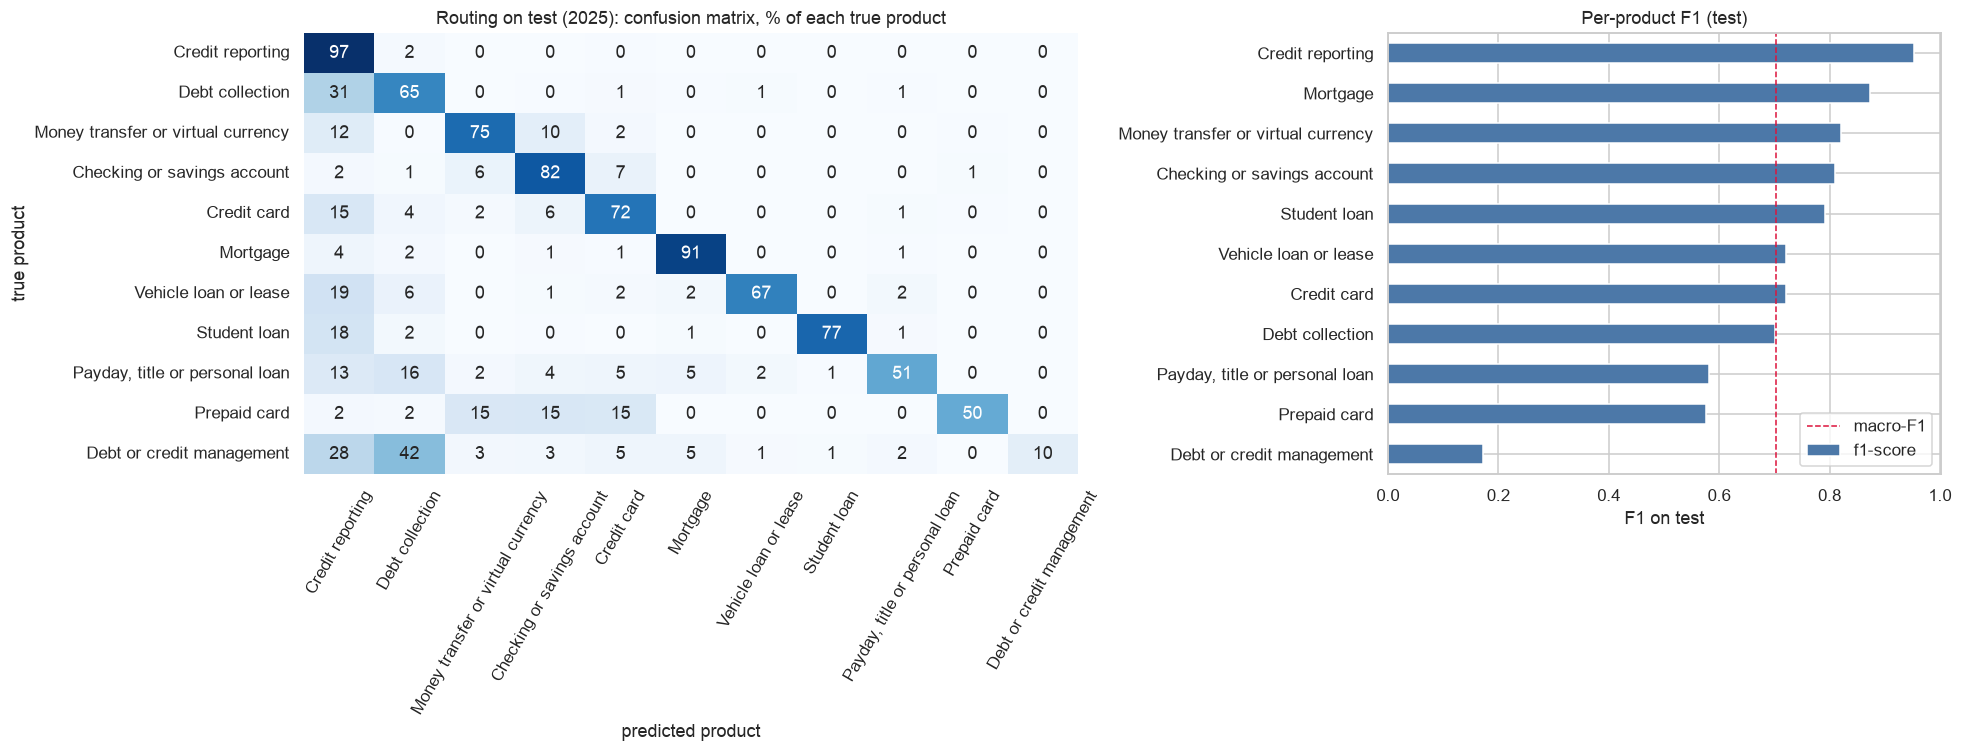

In [19]:
report = pd.DataFrame(classification_report(y_route["test"], pred_route_test, output_dict=True, zero_division=0)).T
per_class = report.drop(index=["accuracy", "macro avg", "weighted avg"]).sort_values("support", ascending=False)
per_class["support"] = per_class["support"].astype(int)
display(per_class)

labels = per_class.index.tolist()
cm = confusion_matrix(y_route["test"], pred_route_test, labels=labels, normalize="true")
fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [1.4, 1]})
sns.heatmap(cm * 100, annot=True, fmt=".0f", cmap="Blues", xticklabels=labels, yticklabels=labels, cbar=False, ax=axes[0])
axes[0].set_xlabel("predicted product")
axes[0].set_ylabel("true product")
axes[0].set_title("Routing on test (2025): confusion matrix, % of each true product")
axes[0].tick_params(axis="x", rotation=60)
per_class["f1-score"].sort_values().plot(kind="barh", ax=axes[1], color="#4C78A8")
axes[1].axvline(report.loc["macro avg", "f1-score"], color="crimson", ls="--", lw=1, label="macro-F1")
axes[1].set_xlabel("F1 on test")
axes[1].set_title("Per-product F1 (test)")
axes[1].legend()
savefig("24_routing_test_confusion_and_f1")

**Per-product routing (test)**
- **Strong:** credit reporting (F1 0.95), mortgage (0.87), money transfer (0.82), checking/savings (0.81) and student loans (0.79) have distinctive vocabularies.
- **Debt collection (0.70):** 31% of its complaints are predicted as credit reporting. Collections show up *on* credit reports, so consumers describe them in credit-report language.
- **Weakest:**
  - *Debt or credit management* (F1 0.17, recall 10%): credit-repair and debt-settlement complaints read like debt-collection (42%) and credit-report (28%) complaints, and it is the smallest class (538 in test).
  - *Prepaid card* (0.58): spread evenly over money transfer, checking and credit card.
  - *Payday/personal loans* (0.58).
- These are the classes to target next, through class-specific features, a second-stage classifier, or simply routing them to a shared queue.

### 10.2 Relief on test: ranking quality, by product, and the sensitivity check
- **Precision at k:** if reviewers can only read the top *k*% of complaints, what share of those would be relief cases?
- **Within products:** the proposal warns that a model can score well "just by recognising the product". AP is therefore also computed *within* each large product, where the product cannot help.
- **Sensitivity:** the same final model, re-scored on test with non-monetary closures counted as negatives.

,final model,structured-only reference,base rate
top 1%,0.4601,0.4286,0.0220
top 2%,0.3822,0.3554,0.0220
top 5%,0.2617,0.2512,0.0220
top 10%,0.1887,0.1852,0.0220
top 20%,0.1082,0.1084,0.0220
top 30%,0.0728,0.0729,0.0220
top 50%,0.0439,0.0439,0.0220


,n,positives,base_rate,AP final,AP structured-only,final / structured
product,,,,,,
Credit reporting,83996,90,0.0011,0.1779,0.0471,3.7805
Debt collection,13489,38,0.0028,0.1435,0.0470,3.0547
Money transfer or virtual currency,12548,287,0.0229,0.2406,0.2333,1.0310
Checking or savings account,9854,1008,0.1023,0.2617,0.2240,1.1685
Credit card,7153,1330,0.1859,0.4150,0.3970,1.0454
Mortgage,2717,45,0.0166,0.1205,0.0722,1.6688
Vehicle loan or lease,2233,45,0.0202,0.0748,0.0838,0.8922
"Payday, title or personal loan",1451,39,0.0269,0.2165,0.1576,1.3738
Prepaid card,736,91,0.1236,0.4259,0.4268,0.9979


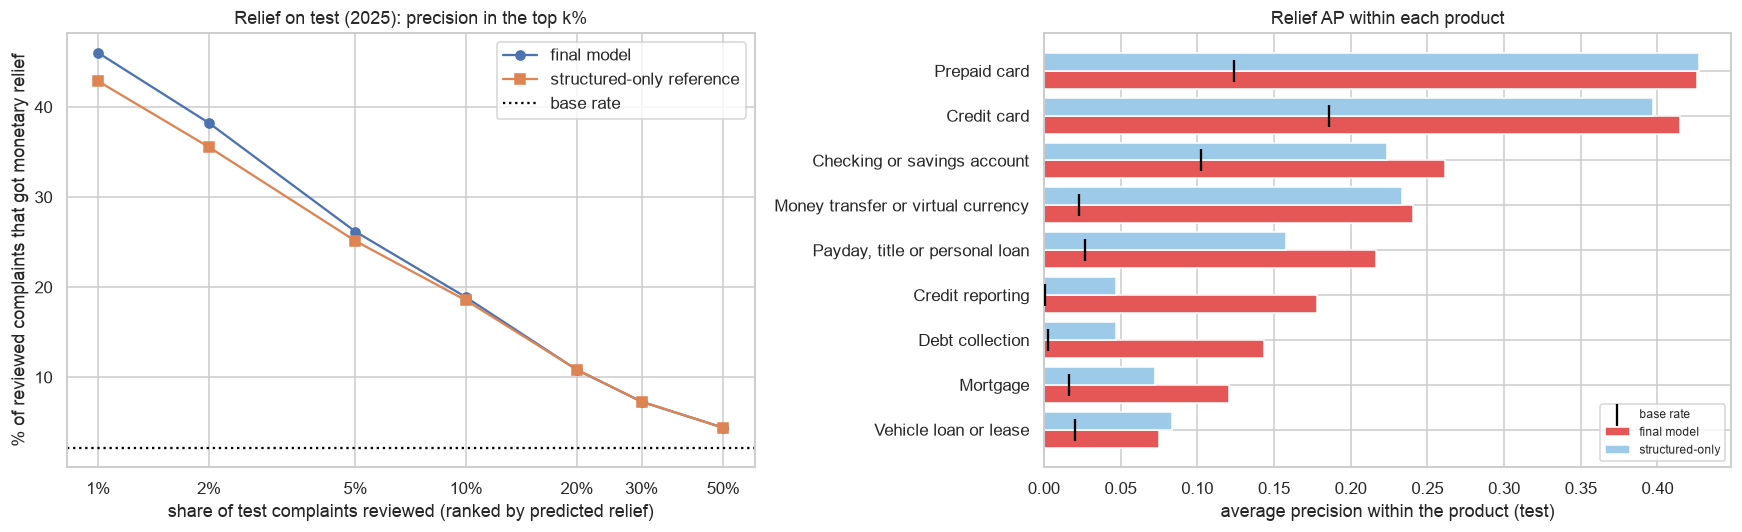

,AP,P@10%,lift@10%,ROC_AUC,base_rate,n,positives
proposal definition (explanation = 0),0.3220,0.1887,8.5886,0.9588,0.0220,136440,2997
sensitivity (explanation or non-monetary = 0),0.3082,0.1375,9.4094,0.9707,0.0146,205139,2997


In [20]:
fracs = np.array([0.01, 0.02, 0.05, 0.10, 0.20, 0.30, 0.50])
pk = pd.DataFrame({
    "final model": [precision_at_frac(y_rel["test"], score_rel_test, f) for f in fracs],
    "structured-only reference": [precision_at_frac(y_rel["test"], score_ref_test, f) for f in fracs],
}, index=[f"top {f:.0%}" for f in fracs])
pk["base rate"] = y_rel["test"].mean()
display(pk)

# AP within each product with enough positives in test
rows = []
prod_test = rel["test"]["product_clean"].to_numpy()
for prod in pd.Series(prod_test).value_counts().index:
    m = prod_test == prod
    pos = int(y_rel["test"][m].sum())
    if pos < 30 or pos == m.sum():
        continue
    rows.append({"product": prod, "n": int(m.sum()), "positives": pos, "base_rate": y_rel["test"][m].mean(),
                 "AP final": average_precision_score(y_rel["test"][m], score_rel_test[m]),
                 "AP structured-only": average_precision_score(y_rel["test"][m], score_ref_test[m])})
by_product = pd.DataFrame(rows).set_index("product")
by_product["final / structured"] = by_product["AP final"] / by_product["AP structured-only"]
display(by_product)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].plot(fracs * 100, pk["final model"] * 100, marker="o", label="final model")
axes[0].plot(fracs * 100, pk["structured-only reference"] * 100, marker="s", label="structured-only reference")
axes[0].axhline(y_rel["test"].mean() * 100, color="black", ls=":", label="base rate")
axes[0].set_xscale("log")
axes[0].set_xticks(fracs * 100, [f"{f:.0%}" for f in fracs])
axes[0].set_xlabel("share of test complaints reviewed (ranked by predicted relief)")
axes[0].set_ylabel("% of reviewed complaints that got monetary relief")
axes[0].set_title("Relief on test (2025): precision in the top k%")
axes[0].legend()
bp = by_product.sort_values("AP final")
y = np.arange(len(bp))
axes[1].barh(y - 0.2, bp["AP final"], height=0.4, label="final model", color="#E45756")
axes[1].barh(y + 0.2, bp["AP structured-only"], height=0.4, label="structured-only", color="#9ecae9")
axes[1].scatter(bp["base_rate"], y, color="black", marker="|", s=200, label="base rate", zorder=3)
axes[1].set_yticks(y, bp.index)
axes[1].set_xlabel("average precision within the product (test)")
axes[1].set_title("Relief AP within each product")
axes[1].legend(fontsize=8)
savefig("25_relief_test_precision_at_k_and_by_product")

# Sensitivity check: non-monetary relief counted as a negative (same model, same test period, same grouping)
sens = test[test["relief_sens"].notna()].reset_index(drop=True)
y_sens = sens["relief_sens"].astype(int).to_numpy()
s_sens = final_rel.predict_proba(sens)[:, 1]
record("relief", f"FINAL: {FINAL_REL['model']} [sensitivity: non-monetary = 0]", FINAL_REL["features"], "test",
       relief_scores(y_sens, s_sens), params=FINAL_REL["params"])
display(pd.DataFrame([relief_scores(y_rel["test"], score_rel_test), relief_scores(y_sens, s_sens)],
                     index=["proposal definition (explanation = 0)", "sensitivity (explanation or non-monetary = 0)"]))

**Relief on test: where the narrative helps**
- **Top of the queue:** the gain from the text is concentrated at the very top of the ranking. In the top 1% of complaints, 46% are relief cases against 43% for structured-only; in the top 2%, 38% vs 36%. From the top 10% downwards, the two models are equal.
- **Within products**, where the product cannot help, the narrative matters most in the products that rarely give relief:
  - **credit reporting:** AP 0.178 vs 0.047 (3.8×)
  - **debt collection:** 0.144 vs 0.047 (3.1×)
  - **mortgage:** 0.121 vs 0.072
  - **payday loans:** 0.217 vs 0.158

  In the high-relief products (credit card, prepaid, money transfer) company and issue already rank well, and the text adds little. For vehicle loans it is slightly worse (0.075 vs 0.084, only 45 positives).
- **So the answer to the proposal's question** ("does the narrative add information beyond the form?") is **yes, but mostly by finding the rare relief cases inside low-relief products.** Overall AP gains little, because the overall ranking is dominated by which product and company a complaint is about.
- **Sensitivity check:** counting non-monetary relief as a negative gives AP 0.308 (vs 0.322), with a lower base rate (1.5%) and *higher* lift at 10% (9.4×). The model's ranking is robust to the choice of negative class.

### 10.3 Out-of-distribution check: January–June 2026
Mature 2026 months, scored once with the same final pipelines. The narrative population changed (opt-in collapsed and credit reporting nearly vanished), so this shows how the models behave under a large shift. It is not used for any decision.

In [21]:
ood_rows = []
ood_route = routing_scores(y_route["ood"], final_route.predict(ood))
record("routing", f"FINAL: {FINAL_ROUTE['model']}", FINAL_ROUTE["features"], "ood2026", ood_route, params=FINAL_ROUTE["params"])
ood_rel = relief_scores(y_rel["ood"], final_rel.predict_proba(rel["ood"])[:, 1])
record("relief", f"FINAL: {FINAL_REL['model']}", FINAL_REL["features"], "ood2026", ood_rel, params=FINAL_REL["params"])
display(pd.DataFrame({"routing (product)": ood_route, "relief": ood_rel}).T)

,macro_F1,weighted_F1,accuracy,n,AP,P@10%,lift@10%,ROC_AUC,base_rate,positives
routing (product),0.6486,0.7739,0.7552,"21,233.0000",NaN,NaN,NaN,NaN,NaN,NaN
relief,NaN,NaN,NaN,"18,450.0000",0.3598,0.3707,4.7303,0.8810,0.0784,"1,446.0000"


**2026 out-of-distribution slice.** Routing macro-F1 falls to 0.65 (accuracy 0.76). Almost no 2026 narratives are about credit reporting, the model's strongest class, and the products that remain are the harder ones. Relief AP is 0.36, but the base rate is 7.8%, so the lift (4.7× at 10%) and ROC-AUC (0.88) are clearly lower than in 2025. Both models degrade under the 2026 population shift. This supports keeping 2026 out of the test set, and it shows a model built on this archive should be re-validated before use on a differently selected population.

### 10.4 What drives the relief predictions, and which relief cases are missed
The coefficients come from a logistic regression on the same features. For a LightGBM final model, the TF-IDF + structured logistic regression from section 8 is used as an interpretable proxy. Large positive weights push a complaint up the review queue. The error analysis looks at **relief cases that the final model ranks outside the top 10%** (false negatives at the operating point a review team would use).

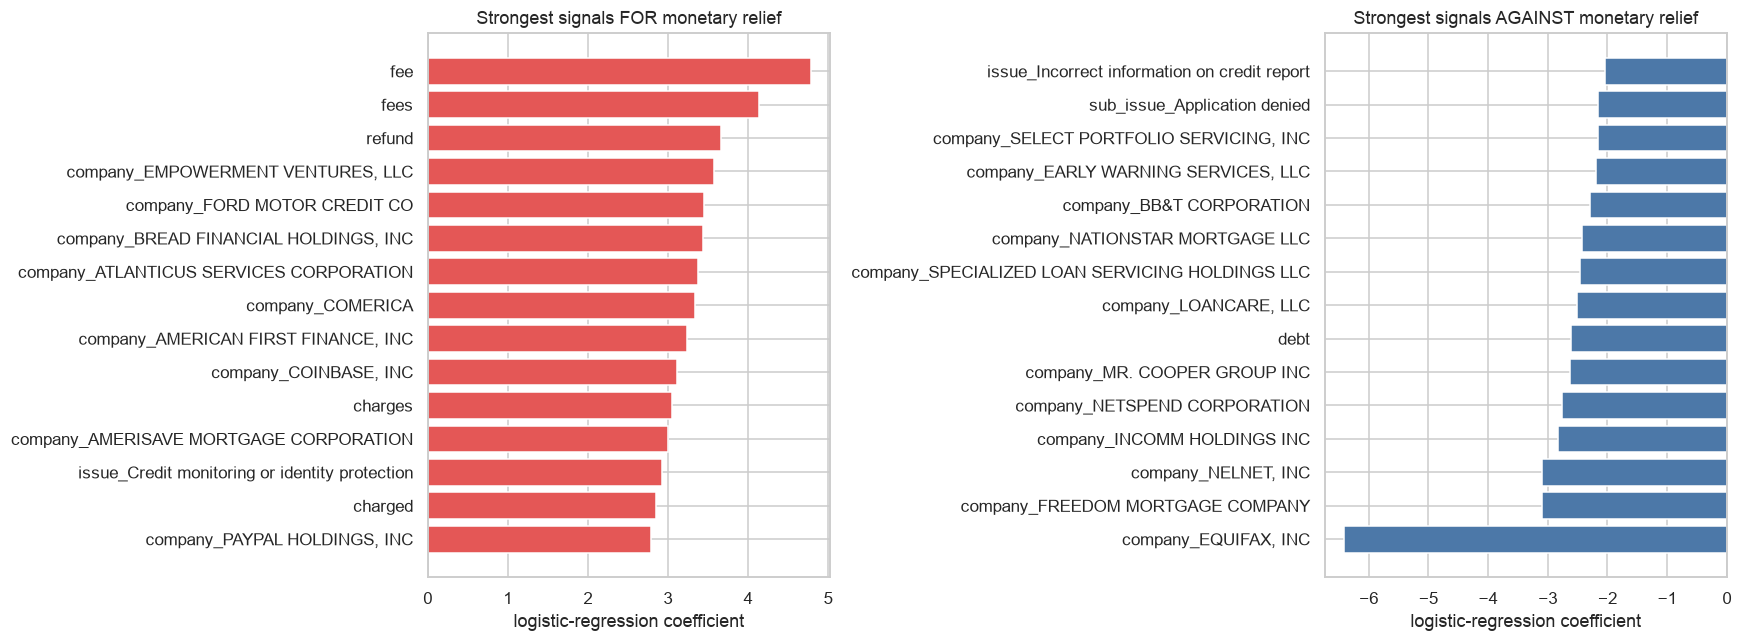

Relief cases in test: 2,997; caught in the top 10%: 2,574 (85.9%); missed: 423


,relief cases,missed,share missed
product_clean,,,
Credit card,1330,79,0.0594
Checking or savings account,1008,104,0.1032
Money transfer or virtual currency,287,55,0.1916
Prepaid card,91,0,0.0000
Credit reporting,90,65,0.7222
Mortgage,45,26,0.5778
Vehicle loan or lease,45,28,0.6222
"Payday, title or personal loan",39,18,0.4615
Debt collection,38,31,0.8158


,median words,share quoting $ amount
caught,204.0000,0.6779
missed,137.0000,0.3168


Most confidently missed relief cases (lowest scores), first 220 characters:
  [Credit reporting | Incorrect information on your report | score 0.001] 'I would like everything removed from my credit report. My credit has been compromised do to a data breach'
  [Credit reporting | Incorrect information on your report | score 0.002] 'I am disputing multiple inaccurate and unverifiable negative items appearing on my credit reports with XXXX, XXXX, and XXXX. The following furnishers are reporting false or incomplete information that is causing ongoing '
  [Credit reporting | Improper use of your report | score 0.002] 'Subject : Complaint Regarding Compromise of Personal Information in XXXX XXXX XXXX Dear Sir/Madam, I am writing to formally lodge a complaint concerning the compromise of my personal information during the XXXX data brea'
  [Debt collection | Attempts to collect debt not owed | score 0.002] 'I am being contacted nearly a full year after returning a rental vehicle from XXXX, wi

In [22]:
coef_model = final_rel if FINAL_REL["model"].endswith("LogReg") and "Structured" not in FINAL_REL["model"] else None
if coef_model is not None:
    names = coef_model.named_steps["prep"].get_feature_names_out()
    coefs = coef_model.named_steps["model"].coef_.ravel()
else:
    names = pre_rel.get_feature_names_out()
    coefs = best_rel_both[2].coef_.ravel()
coef_df = pd.DataFrame({"feature": names, "coef": coefs})
coef_df["feature"] = coef_df["feature"].str.replace(r"^(text|cat|flags|num)__", "", regex=True)
top_pos, top_neg = coef_df.nlargest(15, "coef"), coef_df.nsmallest(15, "coef")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].barh(top_pos["feature"][::-1], top_pos["coef"][::-1], color="#E45756")
axes[0].set_title("Strongest signals FOR monetary relief")
axes[1].barh(top_neg["feature"], top_neg["coef"], color="#4C78A8")
axes[1].set_title("Strongest signals AGAINST monetary relief")
for ax in axes:
    ax.set_xlabel("logistic-regression coefficient")
savefig("26_relief_top_features")

# Error analysis: relief cases ranked below the top-10% cut-off
cut = np.quantile(score_rel_test, 0.90)
ea = rel["test"].assign(score=score_rel_test, y=y_rel["test"])
pos = ea[ea["y"] == 1]
missed = pos[pos["score"] < cut]
print(f"Relief cases in test: {len(pos):,}; caught in the top 10%: {len(pos) - len(missed):,} "
      f"({1 - len(missed) / len(pos):.1%}); missed: {len(missed):,}")
miss_tbl = pd.DataFrame({"relief cases": pos["product_clean"].value_counts(),
                         "missed": missed["product_clean"].value_counts()}).fillna(0).astype(int)
miss_tbl["share missed"] = miss_tbl["missed"] / miss_tbl["relief cases"]
display(miss_tbl.sort_values("relief cases", ascending=False))
display(pd.DataFrame({
    "median words": [pos.loc[~pos.index.isin(missed.index), "word_count"].median(), missed["word_count"].median()],
    "share quoting $ amount": [(pos.loc[~pos.index.isin(missed.index), "n_dollar"] > 0).mean(), (missed["n_dollar"] > 0).mean()],
}, index=["caught", "missed"]))
print("Most confidently missed relief cases (lowest scores), first 220 characters:")
for _, r in missed.nsmallest(5, "score").iterrows():
    print(f"  [{r['product_clean']} | {r['issue'][:40]} | score {r['score']:.3f}] {r['narrative'][:220]!r}")

**What drives relief, and what is missed**
- **Interpretation (LogReg proxy):**
  - Company identity dominates both directions. Equifax is by far the strongest negative, and fintech and card issuers such as Bread, Coinbase and PayPal are positive.
  - The strongest text signals are about money taken: *fee, fees, refund, charges, charged*. *Debt* points the other way.
  - The model therefore partly learns *which companies tend to pay*, a pattern the proposal's constraints anticipated ("the model predicts what the company recorded").
- **Missed relief cases:** 423 of 2,997 relief cases (14%) fall outside the top 10%.
  - The misses come mostly from **low-relief products**: 72% of credit-reporting relief cases are missed, 82% in debt collection and 12 of 13 in student loans.
  - Missed narratives are **shorter** (median 137 vs 204 words) and **less often quote a dollar amount** (32% vs 68%).
  - The most confidently missed cases are generic credit-report disputes. Nothing in their text signals that money was at stake, so their relief outcome is probably due to the company rather than the complaint, and no text model can be expected to find them.

## 11. Save the final models, the metrics file and the comparison table
- `models/routing_final.joblib` and `models/relief_final.joblib`: complete pipelines. The structured-only reference pipelines (`*_structured_reference.joblib`) are saved as well, for the test-set assessment in notebook 03. They take a DataFrame with the raw columns (`narrative`, the categorical fields and the row-wise features from `add_row_features`) and return predictions. The fitted TF-IDF's `stop_words_` attribute (the list of every *discarded* term) is cleared before saving to keep the files small. It is not needed for prediction.
- `reports/model_metrics.csv`: every model, setting and split.
- `reports/model_metrics.md`: the comparison table (best setting per model on validation, plus the single test evaluation).

In [23]:
def slim(pipe):
    for step in pipe.named_steps.values():
        if isinstance(step, ColumnTransformer):
            for _, tr, _ in step.transformers_:
                if isinstance(tr, TfidfVectorizer) and hasattr(tr, "stop_words_"):
                    tr.stop_words_ = None
    return pipe


# The structured-only reference pipelines are saved too, so the test-set assessment (notebook 03) can compare against them
for name, pipe in [("routing_final", final_route), ("relief_final", final_rel),
                   ("routing_structured_reference", ref_route), ("relief_structured_reference", ref_rel)]:
    path = MODEL_DIR / f"{name}.joblib"
    joblib.dump(slim(pipe), path, compress=3)
    print(f"Saved {path.relative_to(ROOT)} ({path.stat().st_size / 1e6:.1f} MB)")

metrics_all = pd.DataFrame(RESULTS)
metrics_all.insert(0, "run_date", pd.Timestamp.today().date().isoformat())
metrics_all.to_csv(REPORT_DIR / "model_metrics.csv", index=False)


def md_table(frame, cols, fmt):
    out = frame[cols].copy()
    for c, f in fmt.items():
        out[c] = out[c].map(lambda v: "" if pd.isna(v) else f.format(v))
    return out.to_markdown(index=False)


test_rows = pd.DataFrame(RESULTS).query("split in ['test', 'ood2026']")
md = ["# Model metrics", "",
      "Generated by `notebooks/02_preprocessing_and_modeling.ipynb`. Validation = 2024-07 to 2024-12, test = 2025, "
      "OOD = 2026-01 to 2026-06. Data: 20% random sample of the CFPB narratives archive, usable narratives only; "
      "repeated narrative text never crosses splits.", "",
      "## Routing (product, 11 classes): validation, best setting per model", "",
      md_table(cmp_route, ["model", "features", "macro_F1", "weighted_F1", "accuracy", "params"],
               {"macro_F1": "{:.4f}", "weighted_F1": "{:.4f}", "accuracy": "{:.4f}"}), "",
      "## Relief (monetary relief vs explanation): validation, best setting per model", "",
      md_table(cmp_rel, ["model", "features", "AP", "P@10%", "lift@10%", "ROC_AUC", "base_rate", "params"],
               {"AP": "{:.4f}", "P@10%": "{:.4f}", "lift@10%": "{:.2f}", "ROC_AUC": "{:.4f}", "base_rate": "{:.4f}"}), "",
      "## Issue (secondary routing target): validation", "",
      md_table(cmp_issue, ["model", "macro_F1", "weighted_F1", "accuracy"],
               {"macro_F1": "{:.4f}", "weighted_F1": "{:.4f}", "accuracy": "{:.4f}"}), "",
      "## Final models: single evaluation on test (2025) and on the 2026 out-of-distribution slice", "",
      md_table(test_rows, ["task", "model", "split", "macro_F1", "accuracy", "AP", "P@10%", "lift@10%", "ROC_AUC", "base_rate", "n"],
               {"macro_F1": "{:.4f}", "accuracy": "{:.4f}", "AP": "{:.4f}", "P@10%": "{:.4f}", "lift@10%": "{:.2f}",
                "ROC_AUC": "{:.4f}", "base_rate": "{:.4f}", "n": "{:,.0f}"}), ""]
(REPORT_DIR / "model_metrics.md").write_text("\n".join(md))
print("Saved reports/model_metrics.csv and reports/model_metrics.md")
display(Markdown("\n".join(md[4:])))

Saved models/routing_final.joblib (5.5 MB)


Saved models/relief_final.joblib (3.3 MB)
Saved models/routing_structured_reference.joblib (0.1 MB)
Saved models/relief_structured_reference.joblib (0.3 MB)
Saved reports/model_metrics.csv and reports/model_metrics.md


## Routing (product, 11 classes): validation, best setting per model

| model                      | features                                                    |   macro_F1 |   weighted_F1 |   accuracy | params                                                       |
|:---------------------------|:------------------------------------------------------------|-----------:|--------------:|-----------:|:-------------------------------------------------------------|
| TF-IDF + structured LogReg | narrative + company, state, zip3, tags, text shape          |     0.7333 |        0.9185 |     0.92   | {'C': 2.0, 'class_weight': None}                             |
| LightGBM                   | chi2 top 20,000 of text + structured, 150,000-row subsample |     0.7134 |        0.9149 |     0.917  | {'num_leaves': 63, 'class_weight': None, 'n_estimators': 93} |
| TF-IDF LogReg              | narrative                                                   |     0.6788 |        0.9007 |     0.904  | {'C': 8.0, 'class_weight': None}                             |
| Structured-only LogReg     | company, state, zip3, tags                                  |     0.557  |        0.8622 |     0.8603 | {'C': 8.0, 'class_weight': None}                             |
| Majority class             | none                                                        |     0.0788 |        0.6639 |     0.7655 |                                                              |

## Relief (monetary relief vs explanation): validation, best setting per model

| model                      | features                                                           |     AP |   P@10% |   lift@10% |   ROC_AUC |   base_rate | params                                                         |
|:---------------------------|:-------------------------------------------------------------------|-------:|--------:|-----------:|----------:|------------:|:---------------------------------------------------------------|
| LightGBM                   | chi2 top 20,000 of text + structured + text shape                  | 0.4057 |  0.2694 |       8.37 |    0.9584 |      0.0322 | {'num_leaves': 31, 'is_unbalance': False, 'n_estimators': 143} |
| TF-IDF + structured LogReg | narrative + all structured + text shape                            | 0.3971 |  0.2701 |       8.39 |    0.9597 |      0.0322 | {'C': 0.25, 'class_weight': 'balanced'}                        |
| Structured-only LightGBM   | product, issue, sub-product, sub-issue, company, state, zip3, tags | 0.3856 |  0.2587 |       8.04 |    0.9553 |      0.0322 | {'num_leaves': 31, 'is_unbalance': True, 'n_estimators': 139}  |
| Structured-only LogReg     | product, issue, sub-product, sub-issue, company, state, zip3, tags | 0.356  |  0.255  |       7.92 |    0.9496 |      0.0322 | {'C': 0.25, 'class_weight': None}                              |
| Base rate (random ranking) | none                                                               | 0.0309 |  0.0317 |       0.98 |    0.4827 |      0.0322 |                                                                |

## Issue (secondary routing target): validation

| model                      |   macro_F1 |   weighted_F1 |   accuracy |
|:---------------------------|-----------:|--------------:|-----------:|
| TF-IDF + structured LogReg |     0.3477 |        0.5923 |     0.6098 |
| Majority class             |     0.0104 |        0.2274 |     0.3988 |

## Final models: single evaluation on test (2025) and on the 2026 out-of-distribution slice

| task    | model                                           | split   |   macro_F1 |   accuracy |     AP |   P@10% |   lift@10% |   ROC_AUC |   base_rate |       n |
|:--------|:------------------------------------------------|:--------|-----------:|-----------:|-------:|--------:|-----------:|----------:|------------:|--------:|
| routing | FINAL: TF-IDF + structured LogReg               | test    |     0.7021 |     0.8995 |        |         |            |           |             | 205,922 |
| routing | Structured-only LogReg (reference)              | test    |     0.5578 |     0.8435 |        |         |            |           |             | 205,922 |
| routing | Majority class (reference)                      | test    |     0.0757 |     0.7129 |        |         |            |           |             | 205,922 |
| relief  | FINAL: LightGBM                                 | test    |            |            | 0.322  |  0.1887 |       8.59 |    0.9588 |      0.022  | 136,440 |
| relief  | Structured-only LightGBM (reference)            | test    |            |            | 0.2962 |  0.1852 |       8.43 |    0.9556 |      0.022  | 136,440 |
| relief  | Base rate (reference)                           | test    |            |            | 0.0226 |  0.0231 |       1.05 |    0.5032 |      0.022  | 136,440 |
| issue   | FINAL: TF-IDF + structured LogReg               | test    |     0.3105 |     0.4793 |        |         |            |           |             | 204,122 |
| issue   | Majority class (reference)                      | test    |     0.0099 |     0.3731 |        |         |            |           |             | 204,122 |
| relief  | FINAL: LightGBM [sensitivity: non-monetary = 0] | test    |            |            | 0.3082 |  0.1375 |       9.41 |    0.9707 |      0.0146 | 205,139 |
| routing | FINAL: TF-IDF + structured LogReg               | ood2026 |     0.6486 |     0.7552 |        |         |            |           |             |  21,233 |
| relief  | FINAL: LightGBM                                 | ood2026 |            |            | 0.3598 |  0.3707 |       4.73 |    0.881  |      0.0784 |  18,450 |


## 12. Summary

**Data and split.**
- Source: 758,548 usable narratives from the 20% archive sample (notebook 01).
- Split by time: train 2015-03 → 2024-06 (404k), validation 2024 H2 (72k), test 2025 (206k).
- Repeated narrative text never crosses a split: 18.6k validation and 33.8k test rows were removed for that reason.
- 2026 is excluded. July–August 2026 outcomes are immature (16% and 56% still in progress). January–June 2026 is a changed population, scored once as an out-of-distribution slice.

**Pre-processing.** Everything is fitted on train only, inside `ColumnTransformer` / `Pipeline`:
- **one-hot encoding** with min-frequency lumping (3,687 companies → 506 columns);
- **log transform and standardisation** of the text-shape counts for the linear models, left unscaled for the trees;
- **TF-IDF** on 1–2-grams (100k terms);
- **χ² selection** (20k columns) for LightGBM.

Post-outcome fields are not loaded at all, and the routing models do not see the product's children (`issue`, `sub_*`).

**Models.** 5 models for routing (majority, structured LogReg, text LogReg, text + structured LogReg, LightGBM), 5 for relief (base rate, structured LogReg, structured LightGBM, text + structured LogReg, LightGBM) and 2 for issue. All were tuned on validation, and every setting is in `reports/model_metrics.csv`.

| | Final model | Validation | **Test (2025)** | Best reference on test |
|---|---|---|---|---|
| Routing (product) | TF-IDF + structured LogReg | macro-F1 0.733 | **0.702** | structured-only 0.558, majority 0.076 |
| Relief | LightGBM, text + structured | AP 0.406 | **AP 0.322**, 86% of relief cases in the top 10% | structured-only LightGBM AP 0.296, base rate 0.022 |
| Issue (secondary) | TF-IDF + structured LogReg | macro-F1 0.348 | 0.311 | majority 0.010 |

**Honest assessment**
- **Routing works well.** It meets the proposal's criterion by a wide margin, and the narrative adds about 0.15 macro-F1 over the form fields. Three small, overlapping classes remain weak: debt or credit management, prepaid card, and payday loans.
- **Relief is learnable but mostly structural.** Product, company and issue already give AP 0.30. The narrative's overall gain is small (+0.03 AP). It is real where it matters operationally: in the top 1–2% of the queue, and inside credit reporting and debt collection, where it lifts AP 3–4×.
  - The overall margin has not been tested for statistical significance. A bootstrap confidence interval is the first item for the next step.
  - The measured relief rate (2–5% depending on the year) is well below the 7–9% AARP figure quoted in the proposal. This is because credit reporting dominates recent years.
- **Issue routing is weak** (macro-F1 0.31), mainly because the issue labels themselves overlap and drift.

**Next steps**
1. Bootstrap confidence intervals for the relief AP gain, and calibration plus threshold analysis for an operating point.
2. Harmonise `issue` labels, then retune issue routing.
3. Sentence embeddings (proposal, "if time allows"), compared against TF-IDF on the same split.
4. Targeted work on the three weak routing classes.
5. Report all results with the limits already noted: opt-in selection, company-recorded labels, and the frozen 2026 archive.